###REWORK
***Are UFO sightings different by location?***

This notebook will be exploring if the sightings distribution and the shapes of the sightings differ by geographical region. This will directly feed into the next phase of the project to compare any potential clustering with rocket launch locations. To start with the time cleaned data set will be imported from an earlier R analyst. The data types of latitude, longitude, and shape will first be examen cleaned and visualized to understand the base line.

Next the Kruskal-Wallis will be used to test categorical data (shape), and numeric data (latitude). From this point the k-means will utilized for determination.



In [1]:
!pip install pyspark
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
%matplotlib inline
import seaborn as sns
from scipy.stats import kruskal

In [2]:
url ="https://raw.githubusercontent.com/zenith-gravity/ufo-sightings-analysis/refs/heads/main/data/ufo_cleaned.csv"
df = pd.read_csv(url)
df.head()

/tmp/ipykernel_1384/3846531110.py:2: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(url)


,datetime,city,state,country,shape,duration..seconds.,duration..hours.min.,comments,date.posted,latitude,longitude,date,time,hour,duration_seconds,log_duration,long_sighting,day_night
0,1949-10-10 20:30:00,san marcos,tx,us,cylinder,2700.0,45 minutes,This event took place in early fall around 194...,2004-04-27,29.883056,-97.941111,1949-10-10,20:30:00,20,2700.0,7.901007,1,Night
1,1949-10-10 21:00:00,lackland afb,tx,NaN,light,7200.0,1-2 hrs,1949 Lackland AFB&#44 TX. Lights racing acros...,2005-12-16,29.38421,-98.581082,1949-10-10,21:00:00,21,7200.0,8.881836,1,Night
2,1955-10-10 17:00:00,chester (uk/england),NaN,gb,circle,20.0,20 seconds,Green/Orange circular disc over Chester&#44 En...,2008-01-21,53.2,-2.916667,1955-10-10,17:00:00,17,20.0,2.995732,0,Day
3,1956-10-10 21:00:00,edna,tx,us,circle,20.0,1/2 hour,My older brother and twin sister were leaving ...,2004-01-17,28.978333,-96.645833,1956-10-10,21:00:00,21,20.0,2.995732,0,Night
4,1960-10-10 20:00:00,kaneohe,hi,us,light,900.0,15 minutes,AS a Marine 1st Lt. flying an FJ4B fighter/att...,2004-01-22,21.418056,-157.803611,1960-10-10,20:00:00,20,900.0,6.802395,1,Night


create a smaller df with only what is needed, and make it operational

In [3]:
ufo_geo = df[["shape", "latitude", "longitude"]].copy()

ufo_geo.head()

,shape,latitude,longitude
0,cylinder,29.883056,-97.941111
1,light,29.38421,-98.581082
2,circle,53.2,-2.916667
3,circle,28.978333,-96.645833
4,light,21.418056,-157.803611


In [4]:
#check the data types
print(ufo_geo.dtypes)
#check the missing values
print("\n Missing values:")
print(ufo_geo.isnull().sum())

shape         object
latitude      object
longitude    float64
dtype: object

 Missing values:
shape        1930
latitude        0
longitude       0
dtype: int64


In [5]:
# Convert coordinates to numerical values
ufo_geo["latitude"] = pd.to_numeric(
    ufo_geo["latitude"],
    errors="coerce"
)

ufo_geo["longitude"] = pd.to_numeric(
    ufo_geo["longitude"],
    errors="coerce"
)

# Examine invalid values
invalid_coords = (
    ufo_geo["latitude"].isna() |
    ufo_geo["longitude"].isna() |
    ~ufo_geo["latitude"].between(-90, 90) |
    ~ufo_geo["longitude"].between(-180, 180)
)

print("Invalid coordinate records:", invalid_coords.sum())
display(df.loc[invalid_coords, ["shape", "latitude", "longitude"]])

Invalid coordinate records: 1


,shape,latitude,longitude
43780,rectangle,33q.200088,-105.624152


It is one recorded in a large dataset, just get rid of it.

In [6]:
ufo_geo = ufo_geo.loc[~invalid_coords].copy()

print("Records remaining:", len(ufo_geo))

Records remaining: 80328


Clean the classifications/catagorical information

In [7]:
# Standardize text
ufo_geo["shape"] = (
    ufo_geo["shape"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Check category counts
shape_counts = (
    ufo_geo["shape"]
    .value_counts(dropna=False)
)

display(shape_counts)


,count
shape,
light,16565
triangle,7865
circle,7607
fireball,6208
other,5649
unknown,5584
sphere,5387
disk,5213
oval,3733


the 3 actions for this data will be


*   Combine other and unknow into a single category called unknown
*   remove missing data (NA)
*   Remove shape catagories with fewer than 10 sightings



In [8]:
ufo_geo_original = ufo_geo.copy()

# 1. Standardize UFO shape names
ufo_geo["shape"] = (
    ufo_geo["shape"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# 2. Combine Other and Unknown
ufo_geo["shape"] = ufo_geo["shape"].replace({
    "other": "unknown"
})

# 3. Remove missing and blank shapes
ufo_geo = ufo_geo.dropna(subset=["shape"]).copy()
ufo_geo = ufo_geo[ufo_geo["shape"] != ""].copy()

# 4. Count sightings for each shape
shape_counts = ufo_geo["shape"].value_counts()

# 5. Keep categories with at least 10 sightings
valid_shapes = shape_counts[shape_counts >= 10].index

ufo_geo = ufo_geo[
    ufo_geo["shape"].isin(valid_shapes)
].copy()

# 6. Verify results
print("Records remaining:", len(ufo_geo))
print("Shape categories remaining:", ufo_geo["shape"].nunique())

display(ufo_geo["shape"].value_counts())

Records remaining: 78382
Shape categories remaining: 20


,count
shape,
light,16565
unknown,11233
triangle,7865
circle,7607
fireball,6208
sphere,5387
disk,5213
oval,3733
formation,2457


In [9]:
# Verify the cleaned data
print("Data types:")
print(ufo_geo.dtypes)

print("\nMissing values:")
print(ufo_geo.isna().sum())



Data types:
shape        string[python]
latitude            float64
longitude           float64
dtype: object

Missing values:
shape        0
latitude     0
longitude    0
dtype: int64


***Graphing the data to get a baseline***

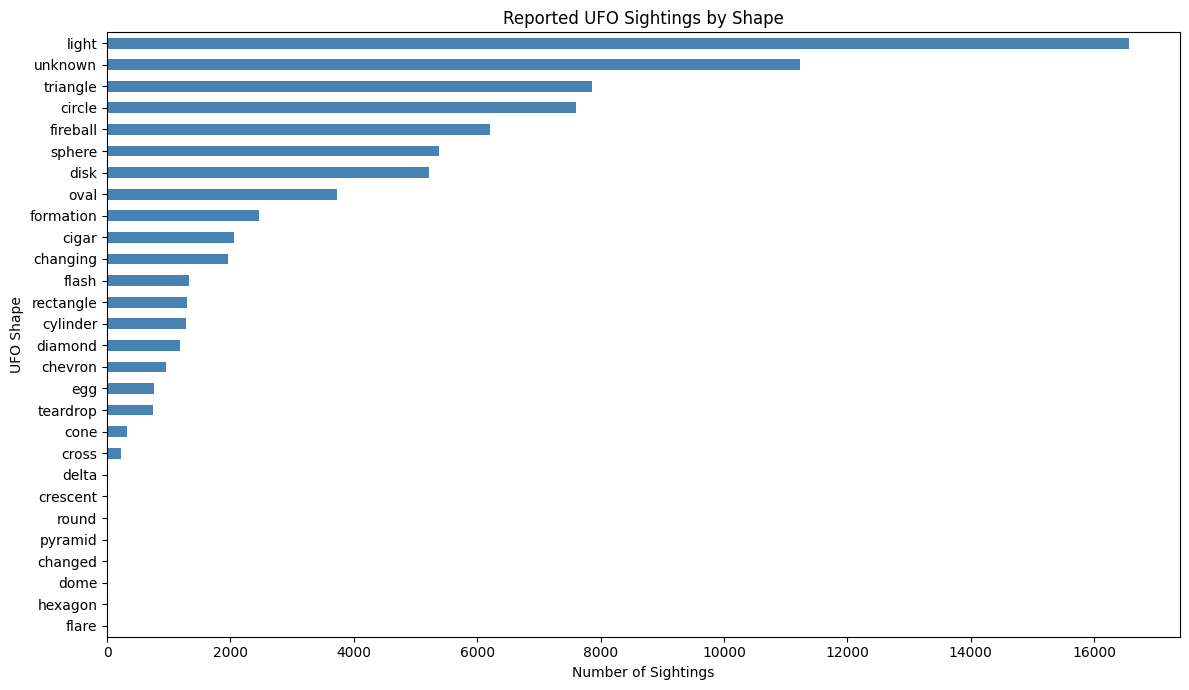

In [10]:
# Create chart
plt.figure(figsize=(12, 7))

shape_counts.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Reported UFO Sightings by Shape")
plt.xlabel("Number of Sightings")
plt.ylabel("UFO Shape")

plt.tight_layout()
plt.show()

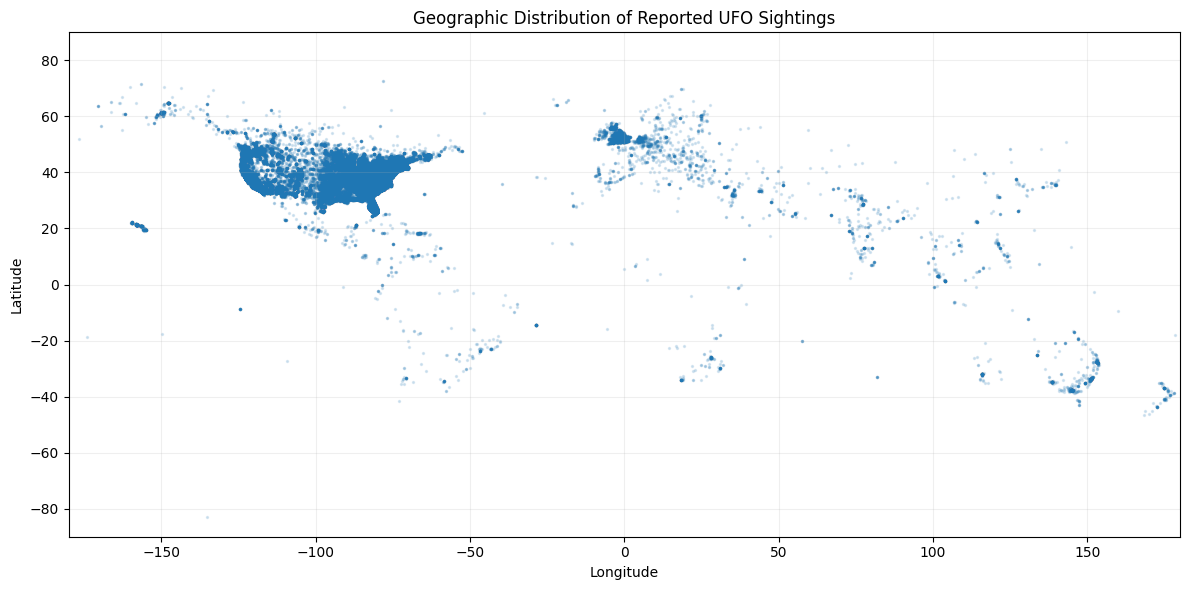

In [11]:
plt.figure(figsize=(12, 6))

plt.scatter(
    ufo_geo["longitude"],
    ufo_geo["latitude"],
    s=2,
    alpha=0.15
)

plt.title("Geographic Distribution of Reported UFO Sightings")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

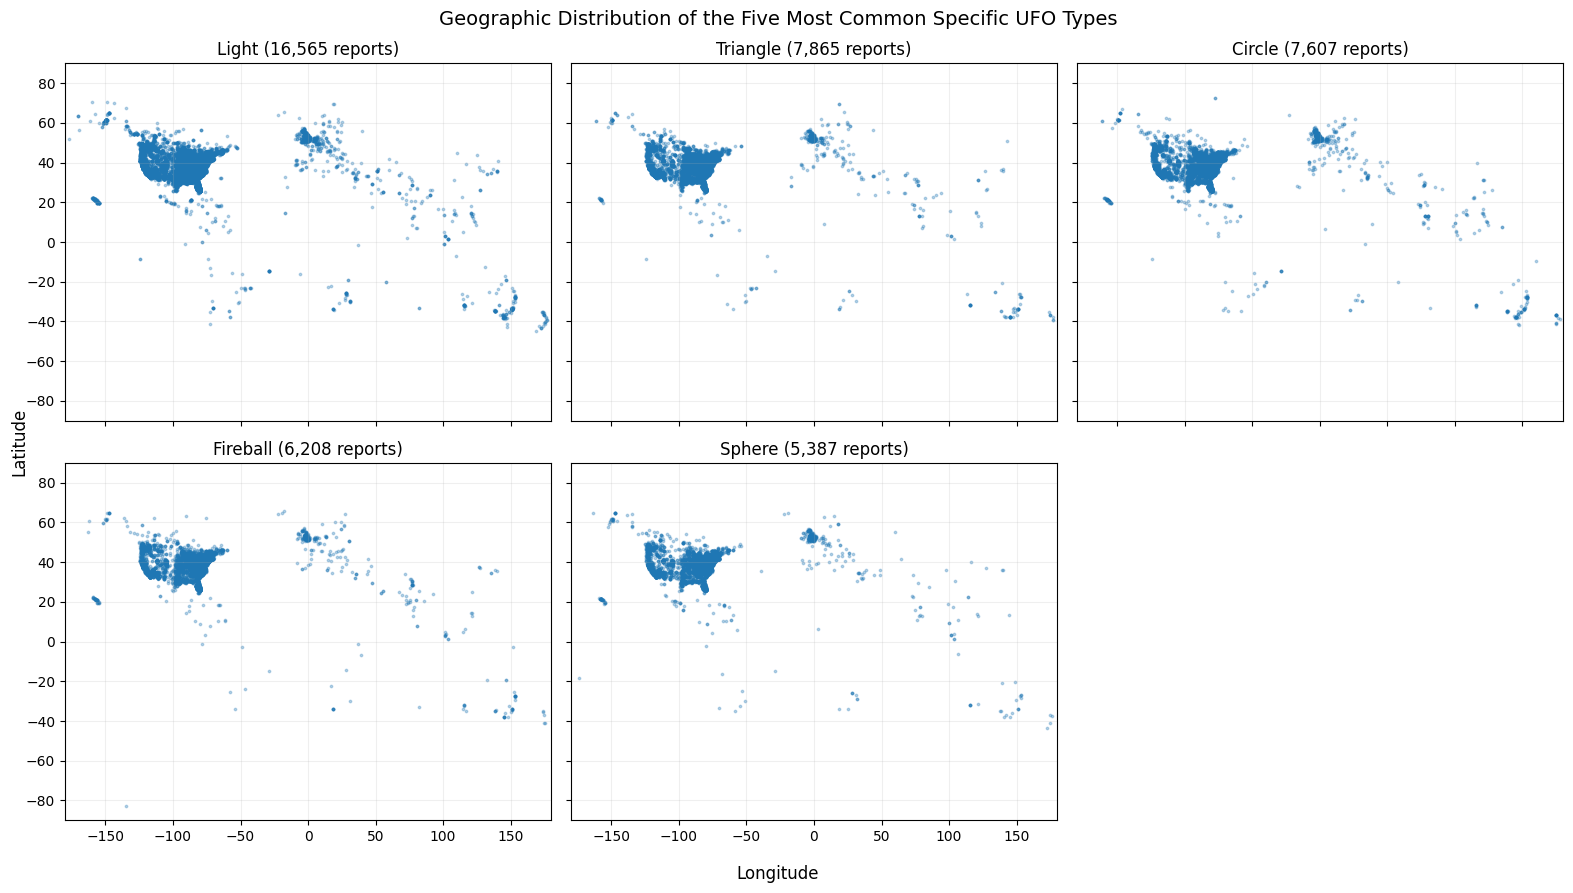

In [12]:
import matplotlib.pyplot as plt

# Select the five most frequent specific UFO types
top_shapes = (
    ufo_geo.loc[ufo_geo["shape"] != "unknown", "shape"]
    .value_counts()
    .head(5)
    .index
)

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9),
    sharex=True,
    sharey=True
)

for ax, shape in zip(axes.flat, top_shapes):
    subset = ufo_geo[ufo_geo["shape"] == shape]

    ax.scatter(
        subset["longitude"],
        subset["latitude"],
        s=3,
        alpha=0.3
    )

    ax.set_title(f"{shape.title()} ({len(subset):,} reports)")
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.grid(alpha=0.2)

# Remove unused subplot
for ax in axes.flat[len(top_shapes):]:
    ax.axis("off")

fig.supxlabel("Longitude")
fig.supylabel("Latitude")
fig.suptitle(
    "Geographic Distribution of the Five Most Common Specific UFO Types",
    fontsize=14
)

plt.tight_layout()
plt.show()

The geographic visualization shows that reported UFO sightings are concentrated in North America and Europe. This imbalance is seen across the top shapes reported along with the collaberation of all shapes.

This must be considered when interpreting statistical test and clustering results. The next step will be to examin the geographix distrution of individual UFO type to determin whether their reposted clocation exhibit distinguishable patterns.

Strong consideration for narrowing the focus to North America is present.

**Kruskal-Wallis Testing**

The Hypotheses are:
 * H0: All five UFO shape categories have the same latitude distribution
 * H1: At least one shape category has a different latitude distribution.

In [13]:
#  common specific shapes
top_shapes = (
    ufo_geo.loc[ufo_geo["shape"] != "unknown", "shape"]
    .value_counts()
    .head(20)
    .index
)

# Prepare latitude data for each category
latitude_groups = [
    ufo_geo.loc[
        ufo_geo["shape"] == shape,
        "latitude"
    ].dropna().values
    for shape in top_shapes
]

# Perform Kruskal-Wallis test
h_stat, p_value = kruskal(*latitude_groups)

print(f"H-statistic: {h_stat:.3f}")
print(f"P-value: {p_value:.6g}")

H-statistic: 52.148
P-value: 3.55043e-05


The p-value is 0.0000355043 is considerably smaller than 0.05 we reject the null hypothesis. This provides evidence that reported UFO shape and latitude are not entirely independent in the way assessed with Kruskal-Wallis test.

However it dose not establish that the dirrerences are large or meaningful.

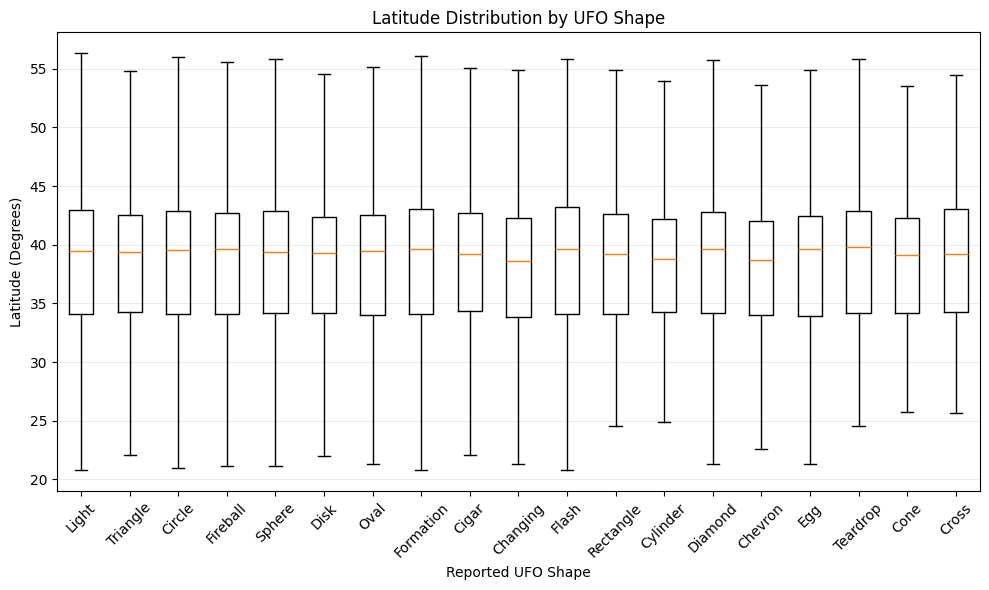

In [14]:
data = [
    ufo_geo.loc[
        ufo_geo["shape"] == shape,
        "latitude"
    ].dropna()
    for shape in top_shapes
]

plt.figure(figsize=(10, 6))

plt.boxplot(
    data,
    tick_labels=[s.title() for s in top_shapes],
    showfliers=False
)

plt.title("Latitude Distribution by UFO Shape")
plt.xlabel("Reported UFO Shape")
plt.xticks(rotation=45)
plt.ylabel("Latitude (Degrees)")
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

From the boxplot we see that all median latitudes are approximately bettween 37-40 degrees. the interquartile ranges overlap heavily across all categories.

For Kruskal–Wallis, one commonly used estimate is epsilon-squared:
\[
\epsilon^2 = \frac{H-k+1}{N-k}
\]

Where:
- \(H\) = Kruskal–Wallis statistic
- \(k\) = number of groups
- \(N\) = total number of observations included in the test


In [15]:
# Calculate Kruskal-Wallis effect size
k = len(latitude_groups)
N = sum(len(group) for group in latitude_groups)

epsilon_squared = max(
    0, (h_stat - k + 1) / (N - k)
)

print(f"Groups analyzed: {k}")
print(f"Total observations: {N:,}")
print(f"Epsilon-squared: {epsilon_squared:.6f}")

Groups analyzed: 19
Total observations: 67,149
Epsilon-squared: 0.000509


In [16]:
print("Categories in test:", len(top_shapes))
print("Categories:", list(top_shapes))
print("Observations tested:", sum(len(g) for g in latitude_groups))

Categories in test: 19
Categories: ['light', 'triangle', 'circle', 'fireball', 'sphere', 'disk', 'oval', 'formation', 'cigar', 'changing', 'flash', 'rectangle', 'cylinder', 'diamond', 'chevron', 'egg', 'teardrop', 'cone', 'cross']
Observations tested: 67149


### Kruskal–Wallis Results and Interpretation

A Kruskal–Wallis test was conducted to determine whether latitude distributions differed across 19 reported UFO shape categories, using 67,149 observations.

The test produced an H-statistic of 52.148 and a p-value of 3.55 × 10⁻⁵. Since the p-value is below the significance threshold of 0.05, the null hypothesis was rejected. This indicates that at least one UFO shape category differs in its latitude rank distribution.

However, the epsilon-squared effect-size estimate was only 0.000509, indicating a negligible association. The boxplots support this finding, showing substantial overlap in median latitudes and interquartile ranges across the categories.

These results suggest that although differences in the geographic latitude of UFO reports are statistically detectable, their practical importance is minimal. The large sample size likely contributes to the test's ability to detect small differences.

Because latitude represents only the north–south component of geographic location, a clustering analysis incorporating both latitude and longitude will be conducted to investigate broader spatial patterns.

***K-means clustering***

Preparing Geographic Coordinates for K-Means Clustering

To investigate geographic patterns in reported UFO sightings, latitude and longitude will be converted into three-dimensional Cartesian coordinates (X, Y, Z).

In [17]:
# create different dataframe to perserve
clusterDf =ufo_geo[["shape", "latitude", "longitude"]].copy()

print(clusterDf.dtypes)
print(clusterDf.isnull().sum())
print(clusterDf.head())

shape        string[python]
latitude            float64
longitude           float64
dtype: object
shape        0
latitude     0
longitude    0
dtype: int64
      shape   latitude   longitude
0  cylinder  29.883056  -97.941111
1     light  29.384210  -98.581082
2    circle  53.200000   -2.916667
3    circle  28.978333  -96.645833
4     light  21.418056 -157.803611


In [18]:
# Convert latitude and longitude from degrees to radians
lat = np.radians(clusterDf["latitude"])
lon = np.radians(clusterDf["longitude"])

# Approximate Earth radius in kilometers
R = 6371

# Calculate Cartesian coordinates
clusterDf["X"] = R * np.cos(lat) * np.cos(lon)
clusterDf["Y"] = R * np.cos(lat) * np.sin(lon)
clusterDf["Z"] = R * np.sin(lat)

# Inspect the converted coordinates
display(
    clusterDf[
        ["shape", "latitude", "longitude", "X", "Y", "Z"]
    ].head(10)
)

,shape,latitude,longitude,X,Y,Z
0,cylinder,29.883056,-97.941111,-763.160919,-5470.966846,3174.231904
1,light,29.384210,-98.581082,-828.312862,-5489.221254,3126.018046
2,circle,53.200000,-2.916667,3811.435600,-194.190584,5101.459564
3,circle,28.978333,-96.645833,-645.015861,-5535.919540,3086.614712
4,light,21.418056,-157.803611,-5491.501655,-2240.636579,2326.499150
5,sphere,36.595000,-82.188889,695.178980,-5067.621332,3798.102318
6,circle,51.434722,-3.180000,3965.603103,-220.323078,4981.474758
7,disk,41.117500,-73.408333,1370.541729,-4599.834327,4189.603863
8,disk,33.586111,-86.286111,343.782354,-5296.249895,3524.371114
9,disk,30.294722,-82.984167,671.910736,-5459.800111,3213.838781


In [19]:
# Extract numerical features for clustering
X = clusterDf[["X", "Y", "Z"]].to_numpy()

print("K-means input matrix:", X.shape)
print("First five observations:")
print(X[:5])

K-means input matrix: (78382, 3)
First five observations:
[[ -763.16091948 -5470.96684617  3174.2319038 ]
 [ -828.31286233 -5489.22125409  3126.0180463 ]
 [ 3811.43559973  -194.19058362  5101.45956431]
 [ -645.01586067 -5535.91954037  3086.61471228]
 [-5491.50165485 -2240.63657911  2326.49915005]]


In [20]:
# Select three initial centroids
k = 3

rng = np.random.default_rng(42)

indices = rng.choice(
    len(X),
    size=k,
    replace=False
)

centers = X[indices].copy()

print("Initial centroid coordinates:")
print(centers)

Initial centroid coordinates:
[[ 1531.32803637 -4511.231254    4230.06714107]
 [-2184.52396863 -4655.75959442  3760.50510297]
 [ -683.51705515 -5300.81390732  3467.53765017]]


In [21]:
# Calculate squared Euclidean distances
dist = np.empty((len(X), k))

for i in range(k):
    dist[:, i] = np.sum(
        (X - centers[i]) ** 2,
        axis=1
    )

# Assign each sighting to the closest centroid
clusters = np.argmin(dist, axis=1)

clusterDf["cluster"] = clusters

print("Sightings in each cluster:")
print(clusterDf["cluster"].value_counts().sort_index())

Sightings in each cluster:
cluster
0    30049
1    25340
2    22993
Name: count, dtype: int64


In [22]:
# Create a DataFrame of our numerical coordinates
cluster_data = pd.DataFrame(
    X,
    columns=["X", "Y", "Z"]
)

# Add the cluster assignments
cluster_data["cluster"] = clusters

# Recalculate centroids using the mean
new_centers = (
    cluster_data
    .groupby("cluster")[["X", "Y", "Z"]]
    .mean()
)

print("Updated centroid locations:")
display(new_centers)

Updated centroid locations:


,X,Y,Z
cluster,,,
0,1391.819444,-3971.703196,4144.851567
1,-2338.091640,-3922.028208,3802.652943
2,-18.187776,-5138.726129,3644.039113


In [23]:
# Convert new centroid DataFrame to NumPy array
updated_centers = new_centers.to_numpy()

# Calculate the movement of each centroid
movement = np.linalg.norm(
    updated_centers - centers,
    axis=1
)

for i, distance in enumerate(movement):
    print(f"Cluster {i}: {distance:.2f} km")

print(f"\nMaximum movement: {movement.max():.2f} km")

Cluster 0: 563.75 km
Cluster 1: 750.81 km
Cluster 2: 707.17 km

Maximum movement: 750.81 km


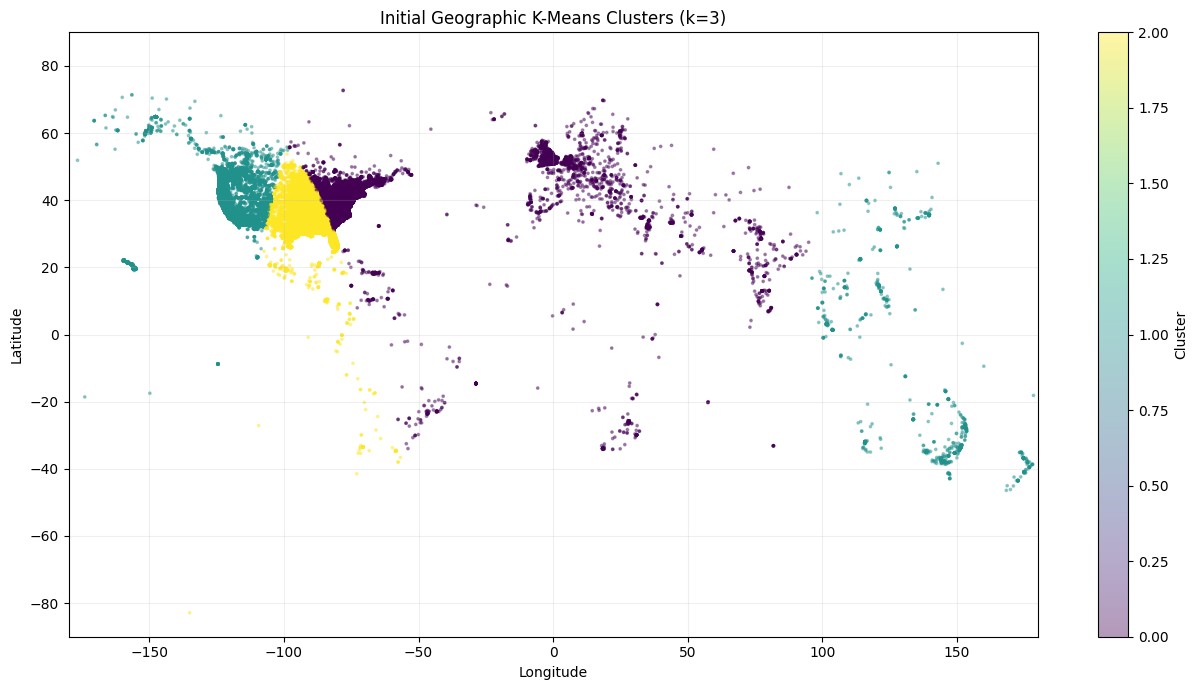

In [24]:
plt.figure(figsize=(13, 7))

plt.scatter(
    clusterDf["longitude"],
    clusterDf["latitude"],
    c=clusterDf["cluster"],
    cmap="viridis",
    s=3,
    alpha=0.4
)

plt.title("Initial Geographic K-Means Clusters (k=3)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.xlim(-180, 180)
plt.ylim(-90, 90)

plt.grid(alpha=0.2)
plt.colorbar(label="Cluster")

plt.tight_layout()
plt.show()

### Initial Cluster Assignment and Centroid Updates

The initial k-means clustering procedure assigned 78,382 UFO sightings to three clusters using their three-dimensional geographic coordinates.

The first iteration assigned 30,049 sightings to Cluster 0, 25,340 to Cluster 1, and 22,993 to Cluster 2.

These initial assignments were based on randomly selected centroids and do not represent the final clustering solution.

Updated centroids were calculated using the mean X, Y, and Z coordinates of the observations assigned to each cluster. The movement of each centroid was then measured to evaluate how much the cluster centers changed.

The next step is to repeat the assignment and centroid-update process until the centroids converge.

In [25]:
# Continue from the updated centroids
centers = updated_centers.copy()

max_iter = 100
tolerance = 0.01  # kilometers

history = []

for iteration in range(max_iter):

    # Step 1: Calculate squared distances
    dist = np.empty((len(X), k))

    for i in range(k):
        dist[:, i] = np.sum(
            (X - centers[i]) ** 2,
            axis=1
        )

    # Step 2: Assign observations to nearest centroid
    clusters = np.argmin(dist, axis=1)

    # Step 3: Update centroids
    new_centers = centers.copy()

    for i in range(k):
        members = X[clusters == i]

        if len(members) > 0:
            new_centers[i] = members.mean(axis=0)
        else:
            raise ValueError("Empty cluster encountered")

    # Step 4: Measure centroid movement
    movement = np.linalg.norm(
        new_centers - centers,
        axis=1
    )

    max_movement = movement.max()

    # Save iteration information
    history.append({
        "iteration": iteration + 1,
        "max_movement": max_movement
    })

    centers = new_centers

    print(
        f"Iteration {iteration + 1}: "
        f"Maximum movement = {max_movement:.4f} km"
    )

    # Step 5: Check for convergence
    if max_movement < tolerance:
        print("Convergence reached!")
        break

# Assign all points to their final nearest centroids
dist = np.empty((len(X), k))

for i in range(k):
    dist[:, i] = np.sum(
        (X - centers[i]) ** 2,
        axis=1
    )

clusters = np.argmin(dist, axis=1)

clusterDf["cluster"] = clusters

# Calculate final WCSS
wcss = np.sum(dist[np.arange(len(X)), clusters])

print(f"\nFinal WCSS: {wcss:,.2f} km²")
print("\nFinal cluster sizes:")
print(clusterDf["cluster"].value_counts().sort_index())

Iteration 1: Maximum movement = 574.4004 km
Iteration 2: Maximum movement = 864.8301 km
Iteration 3: Maximum movement = 3223.2894 km
Iteration 4: Maximum movement = 964.6359 km
Iteration 5: Maximum movement = 130.9533 km
Iteration 6: Maximum movement = 127.1495 km
Iteration 7: Maximum movement = 32.7755 km
Iteration 8: Maximum movement = 4.7061 km
Iteration 9: Maximum movement = 2.3562 km
Iteration 10: Maximum movement = 2.3539 km
Iteration 11: Maximum movement = 2.3560 km
Iteration 12: Maximum movement = 0.0000 km
Convergence reached!

Final WCSS: 199,162,218,891.13 km²

Final cluster sizes:
cluster
0     4531
1    25819
2    48032
Name: count, dtype: int64


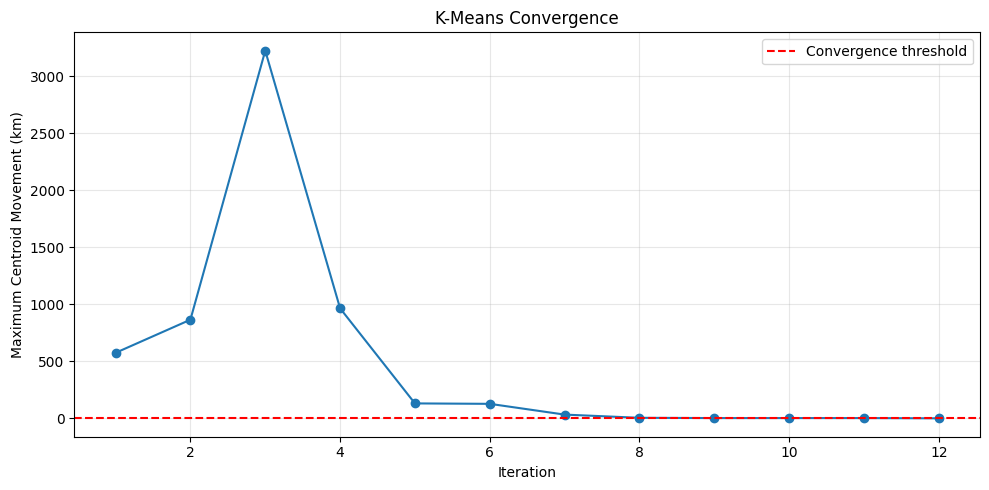

In [26]:
history_df = pd.DataFrame(history)

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["iteration"],
    history_df["max_movement"],
    marker="o"
)

plt.axhline(
    y=tolerance,
    color="red",
    linestyle="--",
    label="Convergence threshold"
)

plt.title("K-Means Convergence")
plt.xlabel("Iteration")
plt.ylabel("Maximum Centroid Movement (km)")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

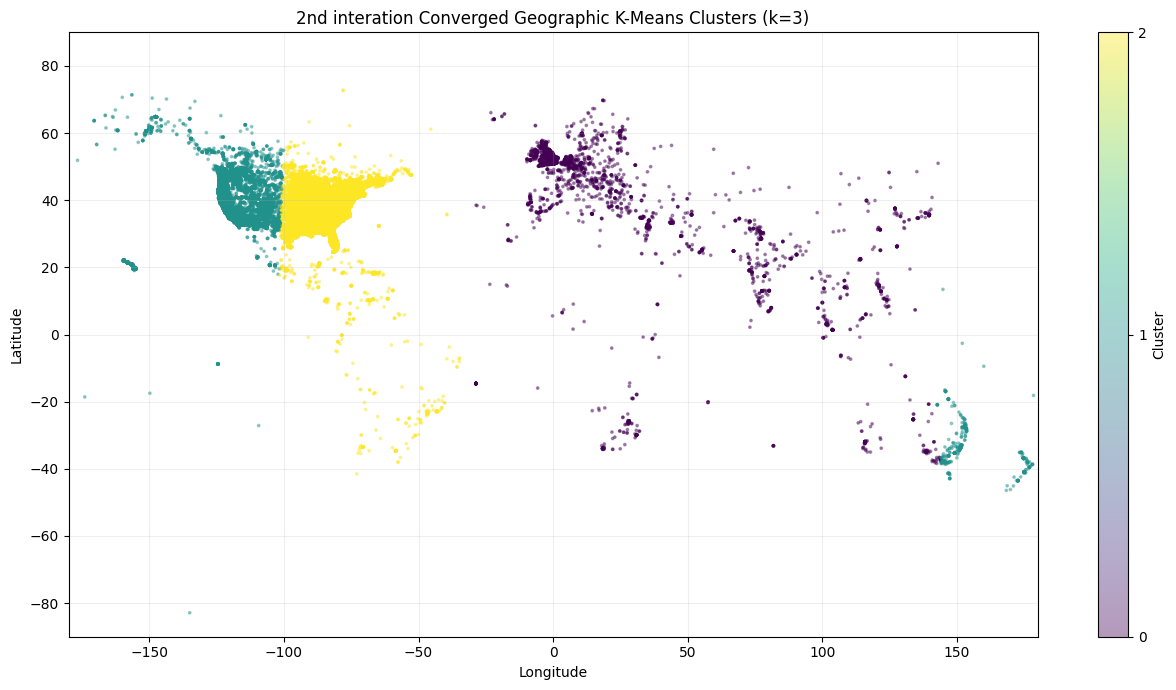

In [27]:
plt.figure(figsize=(13, 7))

plt.scatter(
    clusterDf["longitude"],
    clusterDf["latitude"],
    c=clusterDf["cluster"],
    cmap="viridis",
    s=3,
    alpha=0.4,
    vmin=0,
    vmax=k - 1
)

plt.title(f"2nd interation Converged Geographic K-Means Clusters (k={k})")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.grid(alpha=0.2)

plt.colorbar(
    ticks=range(k),
    label="Cluster"
)

plt.tight_layout()
plt.show()

### Iterative K-Means Clustering

Following the initial cluster assignment, the k-means algorithm was extended to automatically repeat the assignment and centroid-update steps.

During each iteration, squared Euclidean distances were calculated between the sighting coordinates and the current centroids. Observations were reassigned to their nearest centroids, and the centroids were recalculated using the mean coordinates of their assigned observations.

The algorithm continued until the maximum movement of any centroid fell below 0.01 km or the maximum of 100 iterations was reached.

Centroid movement was recorded during each iteration to visualize convergence. The final within-cluster sum of squares (WCSS) was calculated to measure how closely observations were grouped around their assigned centroids.

In [28]:
# Continue from the updated centroids
centers = updated_centers.copy()

max_iter = 100
tolerance = 0.01  # kilometers

history = []

for iteration in range(max_iter):

    # Step 1: Calculate squared distances
    dist = np.empty((len(X), k))

    for i in range(k):
        dist[:, i] = np.sum(
            (X - centers[i]) ** 2,
            axis=1
        )

    # Step 2: Assign observations to nearest centroid
    clusters = np.argmin(dist, axis=1)

    # Step 3: Update centroids
    new_centers = centers.copy()

    for i in range(k):
        members = X[clusters == i]

        if len(members) > 0:
            new_centers[i] = members.mean(axis=0)
        else:
            raise ValueError("Empty cluster encountered")

    # Step 4: Measure centroid movement
    movement = np.linalg.norm(
        new_centers - centers,
        axis=1
    )

    max_movement = movement.max()

    # Save iteration information
    history.append({
        "iteration": iteration + 1,
        "max_movement": max_movement
    })

    centers = new_centers

    print(
        f"Iteration {iteration + 1}: "
        f"Maximum movement = {max_movement:.4f} km"
    )

    # Step 5: Check for convergence
    if max_movement < tolerance:
        print("Convergence reached!")
        break

# Assign all points to their final nearest centroids
dist = np.empty((len(X), k))

for i in range(k):
    dist[:, i] = np.sum(
        (X - centers[i]) ** 2,
        axis=1
    )

clusters = np.argmin(dist, axis=1)

clusterDf["cluster"] = clusters

# Calculate final WCSS
wcss = np.sum(dist[np.arange(len(X)), clusters])

print(f"\nFinal WCSS: {wcss:,.2f} km²")
print("\nFinal cluster sizes:")
print(clusterDf["cluster"].value_counts().sort_index())

Iteration 1: Maximum movement = 574.4004 km
Iteration 2: Maximum movement = 864.8301 km
Iteration 3: Maximum movement = 3223.2894 km
Iteration 4: Maximum movement = 964.6359 km
Iteration 5: Maximum movement = 130.9533 km
Iteration 6: Maximum movement = 127.1495 km
Iteration 7: Maximum movement = 32.7755 km
Iteration 8: Maximum movement = 4.7061 km
Iteration 9: Maximum movement = 2.3562 km
Iteration 10: Maximum movement = 2.3539 km
Iteration 11: Maximum movement = 2.3560 km
Iteration 12: Maximum movement = 0.0000 km
Convergence reached!

Final WCSS: 199,162,218,891.13 km²

Final cluster sizes:
cluster
0     4531
1    25819
2    48032
Name: count, dtype: int64


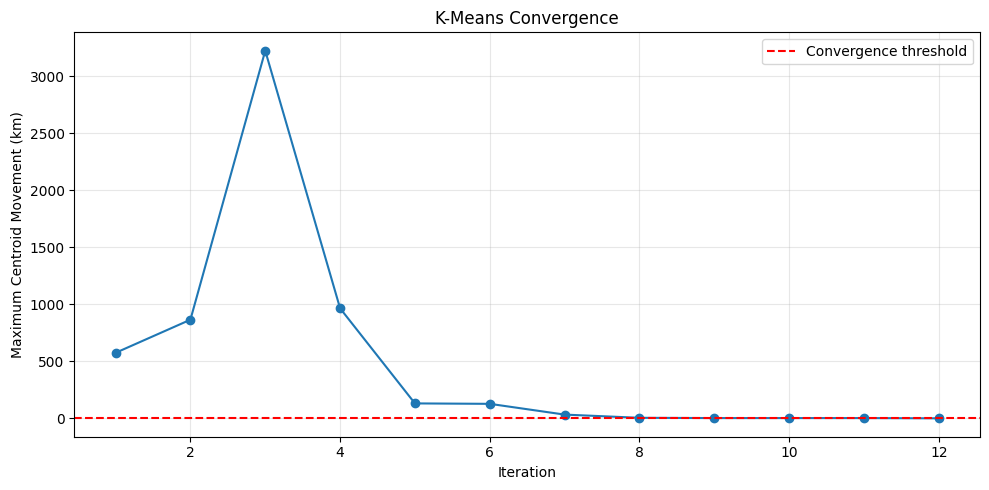

In [29]:
history_df = pd.DataFrame(history)

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["iteration"],
    history_df["max_movement"],
    marker="o"
)

plt.axhline(
    y=tolerance,
    color="red",
    linestyle="--",
    label="Convergence threshold"
)

plt.title("K-Means Convergence")
plt.xlabel("Iteration")
plt.ylabel("Maximum Centroid Movement (km)")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

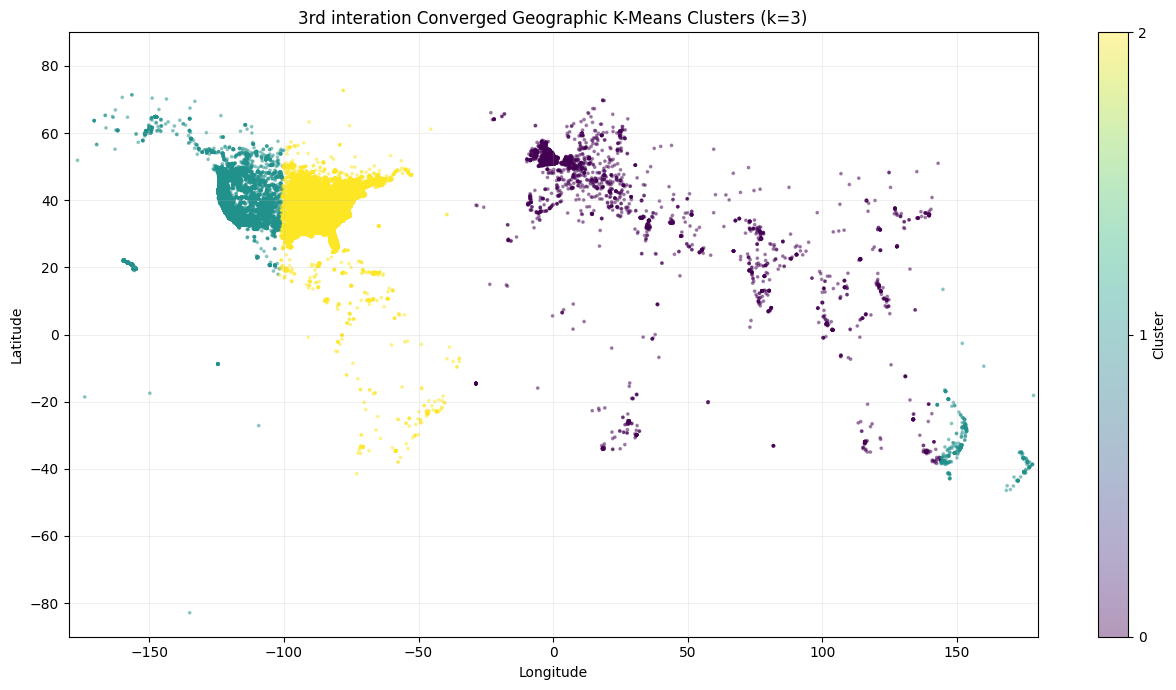

In [30]:
plt.figure(figsize=(13, 7))

plt.scatter(
    clusterDf["longitude"],
    clusterDf["latitude"],
    c=clusterDf["cluster"],
    cmap="viridis",
    s=3,
    alpha=0.4,
    vmin=0,
    vmax=k - 1
)

plt.title(f"3rd interation Converged Geographic K-Means Clusters (k={k})")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.grid(alpha=0.2)

plt.colorbar(
    ticks=range(k),
    label="Cluster"
)

plt.tight_layout()
plt.show()

In [31]:
# Continue from the updated centroids
centers = updated_centers.copy()

max_iter = 100
tolerance = 0.01  # kilometers

history = []

for iteration in range(max_iter):

    # Step 1: Calculate squared distances
    dist = np.empty((len(X), k))

    for i in range(k):
        dist[:, i] = np.sum(
            (X - centers[i]) ** 2,
            axis=1
        )

    # Step 2: Assign observations to nearest centroid
    clusters = np.argmin(dist, axis=1)

    # Step 3: Update centroids
    new_centers = centers.copy()

    for i in range(k):
        members = X[clusters == i]

        if len(members) > 0:
            new_centers[i] = members.mean(axis=0)
        else:
            raise ValueError("Empty cluster encountered")

    # Step 4: Measure centroid movement
    movement = np.linalg.norm(
        new_centers - centers,
        axis=1
    )

    max_movement = movement.max()

    # Save iteration information
    history.append({
        "iteration": iteration + 1,
        "max_movement": max_movement
    })

    centers = new_centers

    print(
        f"Iteration {iteration + 1}: "
        f"Maximum movement = {max_movement:.4f} km"
    )

    # Step 5: Check for convergence
    if max_movement < tolerance:
        print("Convergence reached!")
        break

# Assign all points to their final nearest centroids
dist = np.empty((len(X), k))

for i in range(k):
    dist[:, i] = np.sum(
        (X - centers[i]) ** 2,
        axis=1
    )

clusters = np.argmin(dist, axis=1)

clusterDf["cluster"] = clusters

# Calculate final WCSS
wcss = np.sum(dist[np.arange(len(X)), clusters])

print(f"\nFinal WCSS: {wcss:,.2f} km²")
print("\nFinal cluster sizes:")
print(clusterDf["cluster"].value_counts().sort_index())

Iteration 1: Maximum movement = 574.4004 km
Iteration 2: Maximum movement = 864.8301 km
Iteration 3: Maximum movement = 3223.2894 km
Iteration 4: Maximum movement = 964.6359 km
Iteration 5: Maximum movement = 130.9533 km
Iteration 6: Maximum movement = 127.1495 km
Iteration 7: Maximum movement = 32.7755 km
Iteration 8: Maximum movement = 4.7061 km
Iteration 9: Maximum movement = 2.3562 km
Iteration 10: Maximum movement = 2.3539 km
Iteration 11: Maximum movement = 2.3560 km
Iteration 12: Maximum movement = 0.0000 km
Convergence reached!

Final WCSS: 199,162,218,891.13 km²

Final cluster sizes:
cluster
0     4531
1    25819
2    48032
Name: count, dtype: int64


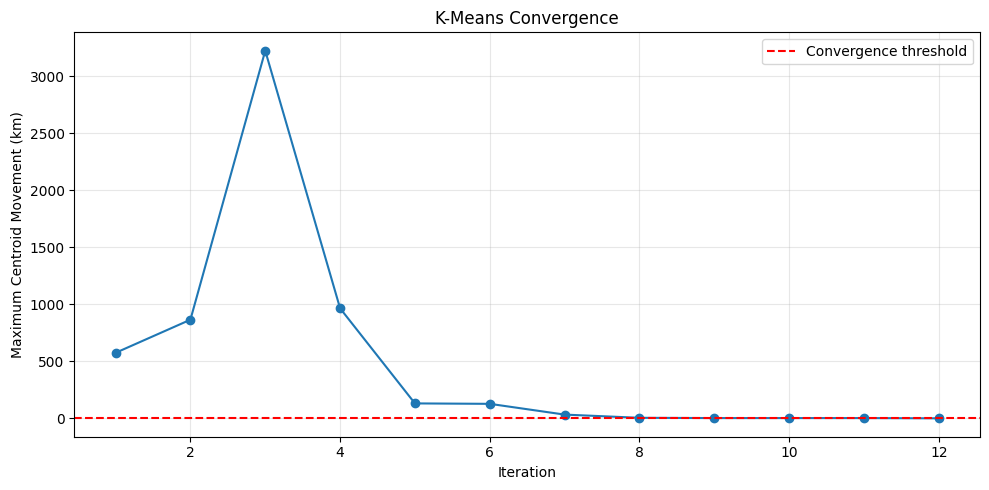

In [32]:
history_df = pd.DataFrame(history)

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["iteration"],
    history_df["max_movement"],
    marker="o"
)

plt.axhline(
    y=tolerance,
    color="red",
    linestyle="--",
    label="Convergence threshold"
)

plt.title("K-Means Convergence")
plt.xlabel("Iteration")
plt.ylabel("Maximum Centroid Movement (km)")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

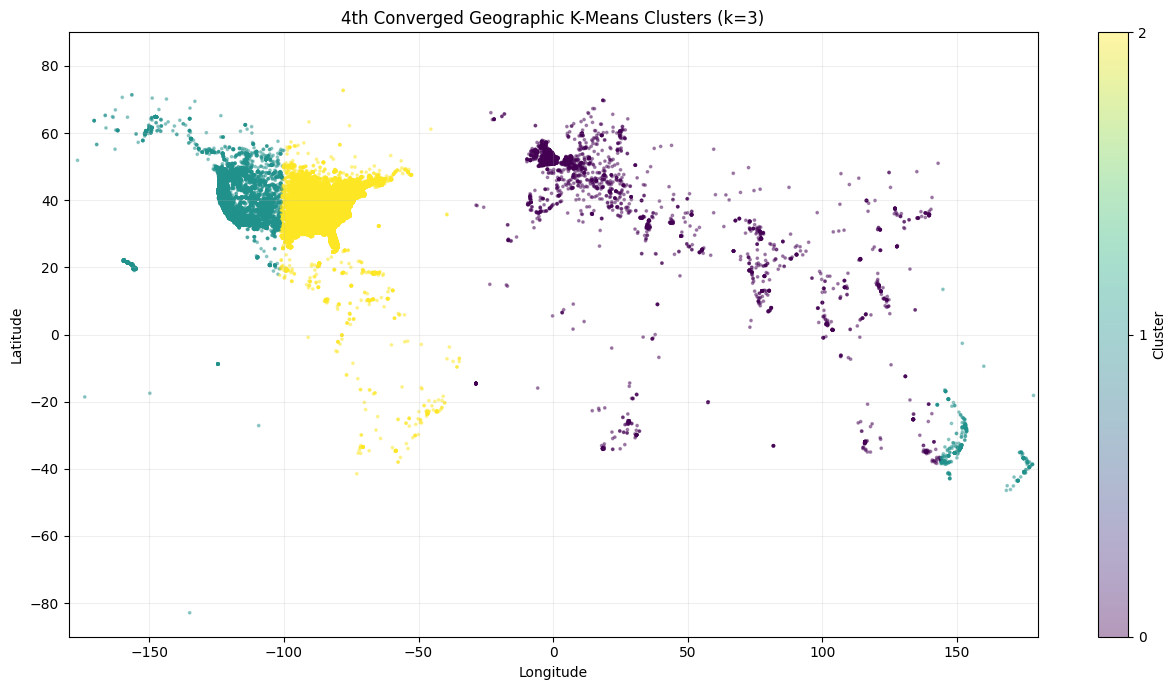

In [33]:
plt.figure(figsize=(13, 7))

plt.scatter(
    clusterDf["longitude"],
    clusterDf["latitude"],
    c=clusterDf["cluster"],
    cmap="viridis",
    s=3,
    alpha=0.4,
    vmin=0,
    vmax=k - 1
)

plt.title(f"4th Converged Geographic K-Means Clusters (k={k})")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.grid(alpha=0.2)

plt.colorbar(
    ticks=range(k),
    label="Cluster"
)

plt.tight_layout()
plt.show()

In [34]:
# Continue from the updated centroids
centers = updated_centers.copy()

max_iter = 100
tolerance = 0.01  # kilometers

history = []

for iteration in range(max_iter):

    # Step 1: Calculate squared distances
    dist = np.empty((len(X), k))

    for i in range(k):
        dist[:, i] = np.sum(
            (X - centers[i]) ** 2,
            axis=1
        )

    # Step 2: Assign observations to nearest centroid
    clusters = np.argmin(dist, axis=1)

    # Step 3: Update centroids
    new_centers = centers.copy()

    for i in range(k):
        members = X[clusters == i]

        if len(members) > 0:
            new_centers[i] = members.mean(axis=0)
        else:
            raise ValueError("Empty cluster encountered")

    # Step 4: Measure centroid movement
    movement = np.linalg.norm(
        new_centers - centers,
        axis=1
    )

    max_movement = movement.max()

    # Save iteration information
    history.append({
        "iteration": iteration + 1,
        "max_movement": max_movement
    })

    centers = new_centers

    print(
        f"Iteration {iteration + 1}: "
        f"Maximum movement = {max_movement:.4f} km"
    )

    # Step 5: Check for convergence
    if max_movement < tolerance:
        print("Convergence reached!")
        break

# Assign all points to their final nearest centroids
dist = np.empty((len(X), k))

for i in range(k):
    dist[:, i] = np.sum(
        (X - centers[i]) ** 2,
        axis=1
    )

clusters = np.argmin(dist, axis=1)

clusterDf["cluster"] = clusters

# Calculate final WCSS
wcss = np.sum(dist[np.arange(len(X)), clusters])

print(f"\nFinal WCSS: {wcss:,.2f} km²")
print("\nFinal cluster sizes:")
print(clusterDf["cluster"].value_counts().sort_index())

Iteration 1: Maximum movement = 574.4004 km
Iteration 2: Maximum movement = 864.8301 km
Iteration 3: Maximum movement = 3223.2894 km
Iteration 4: Maximum movement = 964.6359 km
Iteration 5: Maximum movement = 130.9533 km
Iteration 6: Maximum movement = 127.1495 km
Iteration 7: Maximum movement = 32.7755 km
Iteration 8: Maximum movement = 4.7061 km
Iteration 9: Maximum movement = 2.3562 km
Iteration 10: Maximum movement = 2.3539 km
Iteration 11: Maximum movement = 2.3560 km
Iteration 12: Maximum movement = 0.0000 km
Convergence reached!

Final WCSS: 199,162,218,891.13 km²

Final cluster sizes:
cluster
0     4531
1    25819
2    48032
Name: count, dtype: int64


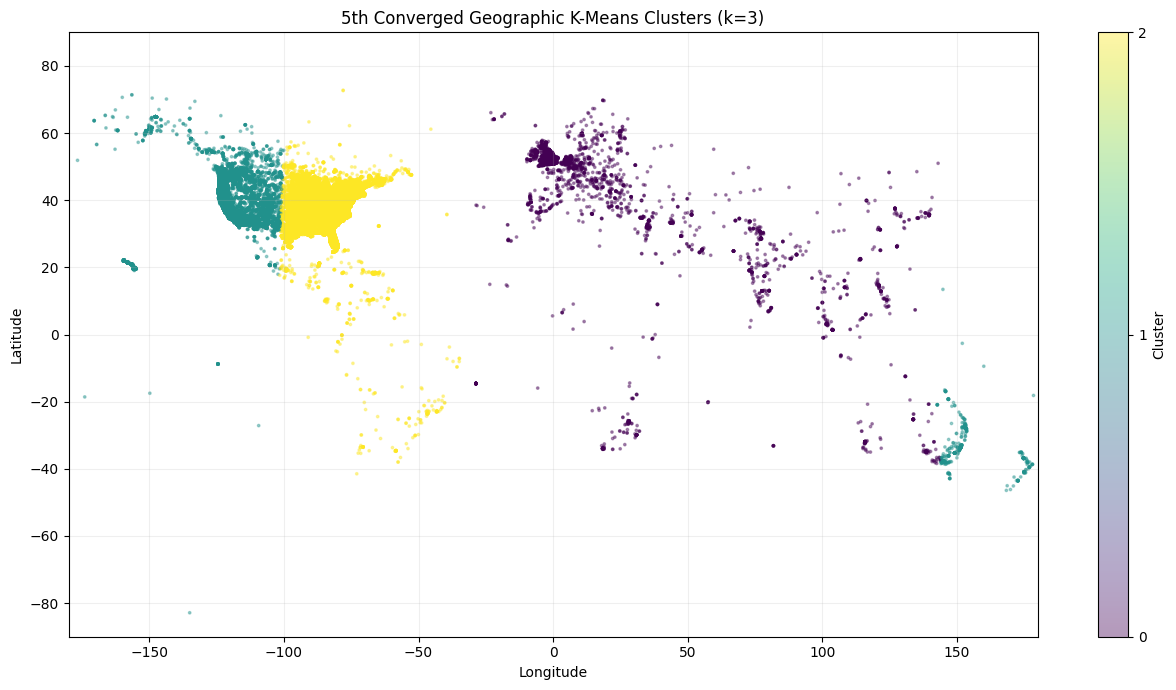

In [35]:
plt.figure(figsize=(13, 7))

plt.scatter(
    clusterDf["longitude"],
    clusterDf["latitude"],
    c=clusterDf["cluster"],
    cmap="viridis",
    s=3,
    alpha=0.4,
    vmin=0,
    vmax=k - 1
)

plt.title(f"5th Converged Geographic K-Means Clusters (k={k})")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.grid(alpha=0.2)

plt.colorbar(
    ticks=range(k),
    label="Cluster"
)

plt.tight_layout()
plt.show()

In [36]:
# Continue from the updated centroids
centers = updated_centers.copy()

max_iter = 100
tolerance = 0.01  # kilometers

history = []

for iteration in range(max_iter):

    # Step 1: Calculate squared distances
    dist = np.empty((len(X), k))

    for i in range(k):
        dist[:, i] = np.sum(
            (X - centers[i]) ** 2,
            axis=1
        )

    # Step 2: Assign observations to nearest centroid
    clusters = np.argmin(dist, axis=1)

    # Step 3: Update centroids
    new_centers = centers.copy()

    for i in range(k):
        members = X[clusters == i]

        if len(members) > 0:
            new_centers[i] = members.mean(axis=0)
        else:
            raise ValueError("Empty cluster encountered")

    # Step 4: Measure centroid movement
    movement = np.linalg.norm(
        new_centers - centers,
        axis=1
    )

    max_movement = movement.max()

    # Save iteration information
    history.append({
        "iteration": iteration + 1,
        "max_movement": max_movement
    })

    centers = new_centers

    print(
        f"Iteration {iteration + 1}: "
        f"Maximum movement = {max_movement:.4f} km"
    )

    # Step 5: Check for convergence
    if max_movement < tolerance:
        print("Convergence reached!")
        break

# Assign all points to their final nearest centroids
dist = np.empty((len(X), k))

for i in range(k):
    dist[:, i] = np.sum(
        (X - centers[i]) ** 2,
        axis=1
    )

clusters = np.argmin(dist, axis=1)

clusterDf["cluster"] = clusters

# Calculate final WCSS
wcss = np.sum(dist[np.arange(len(X)), clusters])

print(f"\nFinal WCSS: {wcss:,.2f} km²")
print("\nFinal cluster sizes:")
print(clusterDf["cluster"].value_counts().sort_index())

Iteration 1: Maximum movement = 574.4004 km
Iteration 2: Maximum movement = 864.8301 km
Iteration 3: Maximum movement = 3223.2894 km
Iteration 4: Maximum movement = 964.6359 km
Iteration 5: Maximum movement = 130.9533 km
Iteration 6: Maximum movement = 127.1495 km
Iteration 7: Maximum movement = 32.7755 km
Iteration 8: Maximum movement = 4.7061 km
Iteration 9: Maximum movement = 2.3562 km
Iteration 10: Maximum movement = 2.3539 km
Iteration 11: Maximum movement = 2.3560 km
Iteration 12: Maximum movement = 0.0000 km
Convergence reached!

Final WCSS: 199,162,218,891.13 km²

Final cluster sizes:
cluster
0     4531
1    25819
2    48032
Name: count, dtype: int64


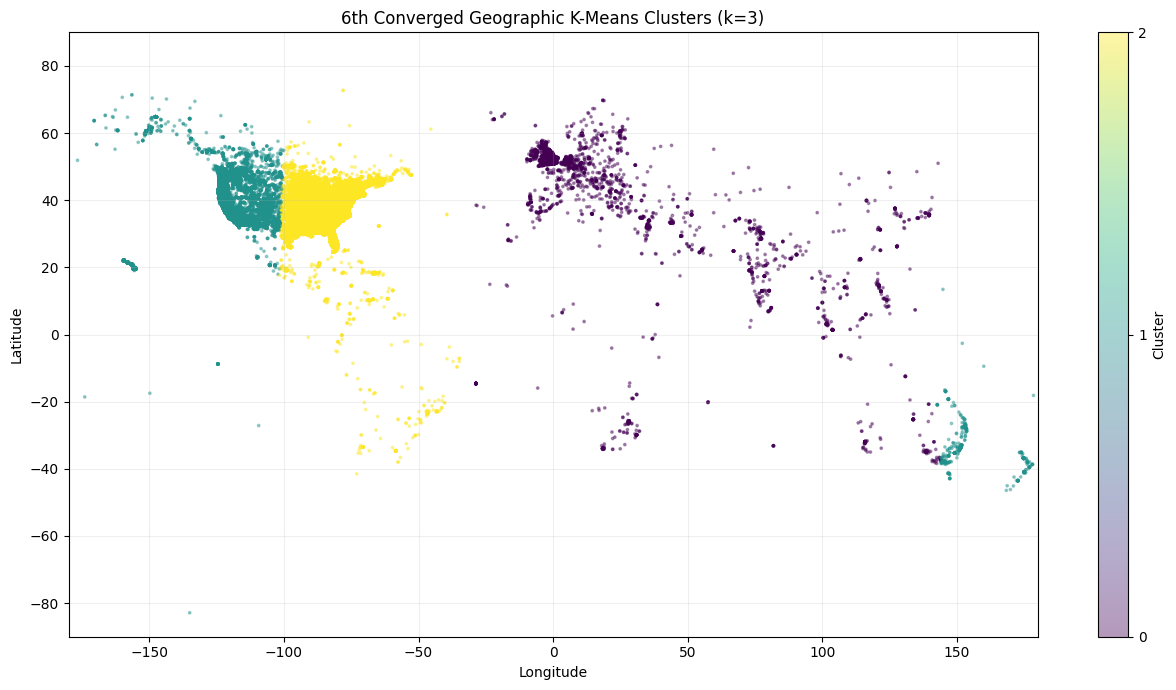

In [37]:
plt.figure(figsize=(13, 7))

plt.scatter(
    clusterDf["longitude"],
    clusterDf["latitude"],
    c=clusterDf["cluster"],
    cmap="viridis",
    s=3,
    alpha=0.4,
    vmin=0,
    vmax=k - 1
)

plt.title(f"6th Converged Geographic K-Means Clusters (k={k})")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.grid(alpha=0.2)

plt.colorbar(
    ticks=range(k),
    label="Cluster"
)

plt.tight_layout()
plt.show()

In [38]:
# Continue from the updated centroids
centers = updated_centers.copy()

max_iter = 100
tolerance = 0.01  # kilometers

history = []

for iteration in range(max_iter):

    # Step 1: Calculate squared distances
    dist = np.empty((len(X), k))

    for i in range(k):
        dist[:, i] = np.sum(
            (X - centers[i]) ** 2,
            axis=1
        )

    # Step 2: Assign observations to nearest centroid
    clusters = np.argmin(dist, axis=1)

    # Step 3: Update centroids
    new_centers = centers.copy()

    for i in range(k):
        members = X[clusters == i]

        if len(members) > 0:
            new_centers[i] = members.mean(axis=0)
        else:
            raise ValueError("Empty cluster encountered")

    # Step 4: Measure centroid movement
    movement = np.linalg.norm(
        new_centers - centers,
        axis=1
    )

    max_movement = movement.max()

    # Save iteration information
    history.append({
        "iteration": iteration + 1,
        "max_movement": max_movement
    })

    centers = new_centers

    print(
        f"Iteration {iteration + 1}: "
        f"Maximum movement = {max_movement:.4f} km"
    )

    # Step 5: Check for convergence
    if max_movement < tolerance:
        print("Convergence reached!")
        break

# Assign all points to their final nearest centroids
dist = np.empty((len(X), k))

for i in range(k):
    dist[:, i] = np.sum(
        (X - centers[i]) ** 2,
        axis=1
    )

clusters = np.argmin(dist, axis=1)

clusterDf["cluster"] = clusters

# Calculate final WCSS
wcss = np.sum(dist[np.arange(len(X)), clusters])

print(f"\nFinal WCSS: {wcss:,.2f} km²")
print("\nFinal cluster sizes:")
print(clusterDf["cluster"].value_counts().sort_index())

Iteration 1: Maximum movement = 574.4004 km
Iteration 2: Maximum movement = 864.8301 km
Iteration 3: Maximum movement = 3223.2894 km
Iteration 4: Maximum movement = 964.6359 km
Iteration 5: Maximum movement = 130.9533 km
Iteration 6: Maximum movement = 127.1495 km
Iteration 7: Maximum movement = 32.7755 km
Iteration 8: Maximum movement = 4.7061 km
Iteration 9: Maximum movement = 2.3562 km
Iteration 10: Maximum movement = 2.3539 km
Iteration 11: Maximum movement = 2.3560 km
Iteration 12: Maximum movement = 0.0000 km
Convergence reached!

Final WCSS: 199,162,218,891.13 km²

Final cluster sizes:
cluster
0     4531
1    25819
2    48032
Name: count, dtype: int64


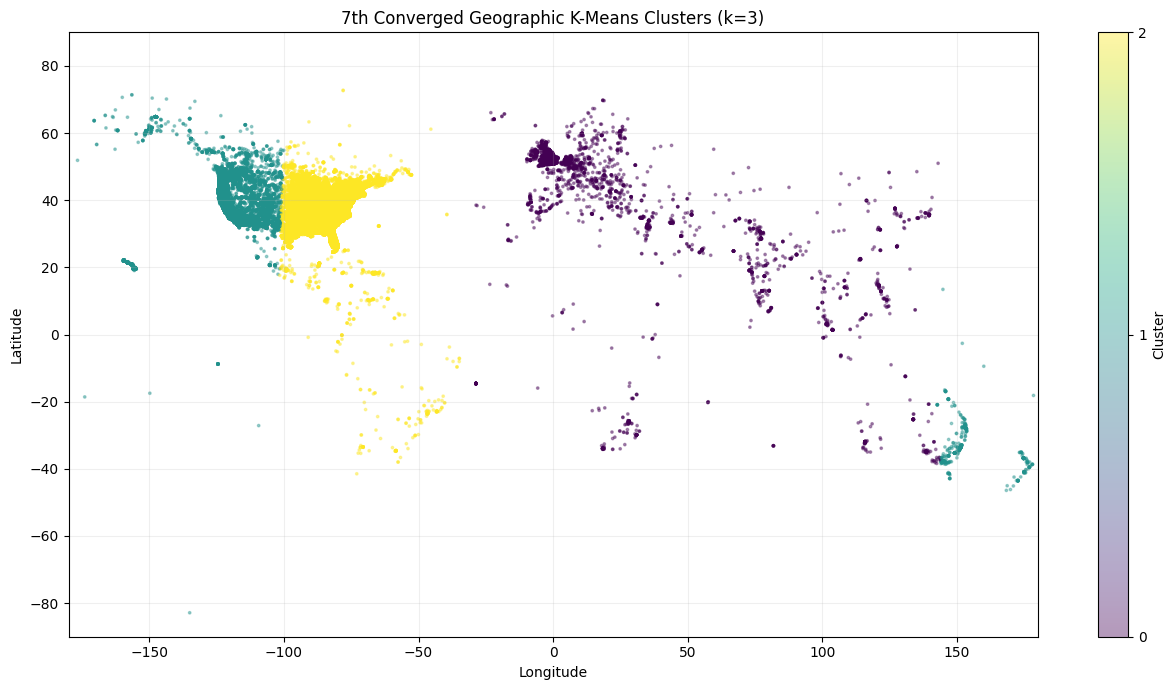

In [39]:
plt.figure(figsize=(13, 7))

plt.scatter(
    clusterDf["longitude"],
    clusterDf["latitude"],
    c=clusterDf["cluster"],
    cmap="viridis",
    s=3,
    alpha=0.4,
    vmin=0,
    vmax=k - 1
)

plt.title(f"7th Converged Geographic K-Means Clusters (k={k})")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.grid(alpha=0.2)

plt.colorbar(
    ticks=range(k),
    label="Cluster"
)

plt.tight_layout()
plt.show()

In [40]:
# Convert iteration history into a DataFrame
history_df = pd.DataFrame(history)

# Display movements for each iteration
display(history_df)

,iteration,max_movement
0,1,574.400366
1,2,864.830056
2,3,3223.289363
3,4,964.635874
4,5,130.953337
5,6,127.149470
6,7,32.775519
7,8,4.706072
8,9,2.356232
9,10,2.353914


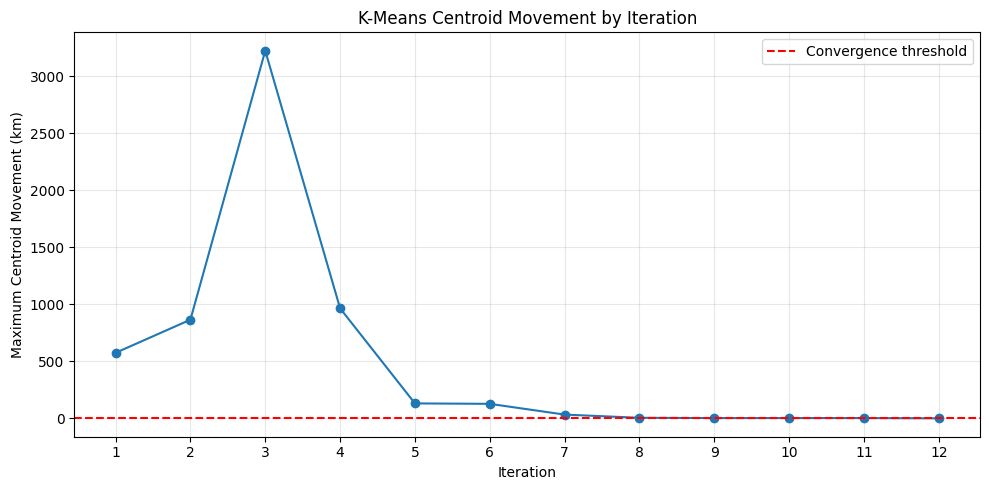

In [41]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_df["iteration"],
    history_df["max_movement"],
    marker="o"
)

plt.axhline(
    y=tolerance,
    color="red",
    linestyle="--",
    label="Convergence threshold"
)

plt.title("K-Means Centroid Movement by Iteration")
plt.xlabel("Iteration")
plt.ylabel("Maximum Centroid Movement (km)")
plt.xticks(history_df["iteration"])
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [42]:
# Before the iteration loop
previous_labels = None

# Inside the loop, immediately after calculating clusters
if previous_labels is not None:
    changes = np.sum(clusters != previous_labels)
    print(f"Cluster assignments changed: {changes}")

previous_labels = clusters.copy()

*K-means convergence observations*

The intinal geographic clusterings changed substantially in the early iterations. The intial cluster were from randomly selected centorids producing 3 groups. The boundaries shifted as the centroids were recalculated.

Around the 5th iteration, the geographic distribution of the clusters were basicaly stable.

Now we are going to try differnt k values.

***Nevermind Dig deeper into the US sightings***

After further review in U.S_ufo_types notebook it was found that 90% of the sightings listed are in the US. This fact of the data set combined with the cenitma dataset applying mostly to the U.S populatation it is belive restricting the scope of this project will be more fruitful

In [43]:
#create a df of a rought box around the US
# This should keep all of the cleaning and combining of types
ufo_us = ufo_geo[
    ufo_geo["latitude"].between(25, 50) &
    ufo_geo["longitude"].between(-125, -67)
].copy()

display(ufo_us.head())

# Verify the cleaned data
print("Data types:")
print(ufo_geo.dtypes)

print("\nMissing values:")
print(ufo_geo.isna().sum())

,shape,latitude,longitude
0,cylinder,29.883056,-97.941111
1,light,29.384210,-98.581082
3,circle,28.978333,-96.645833
5,sphere,36.595000,-82.188889
7,disk,41.117500,-73.408333


Data types:
shape        string[python]
latitude            float64
longitude           float64
dtype: object

Missing values:
shape        0
latitude     0
longitude    0
dtype: int64


**Remake the baseline graphs to compare**

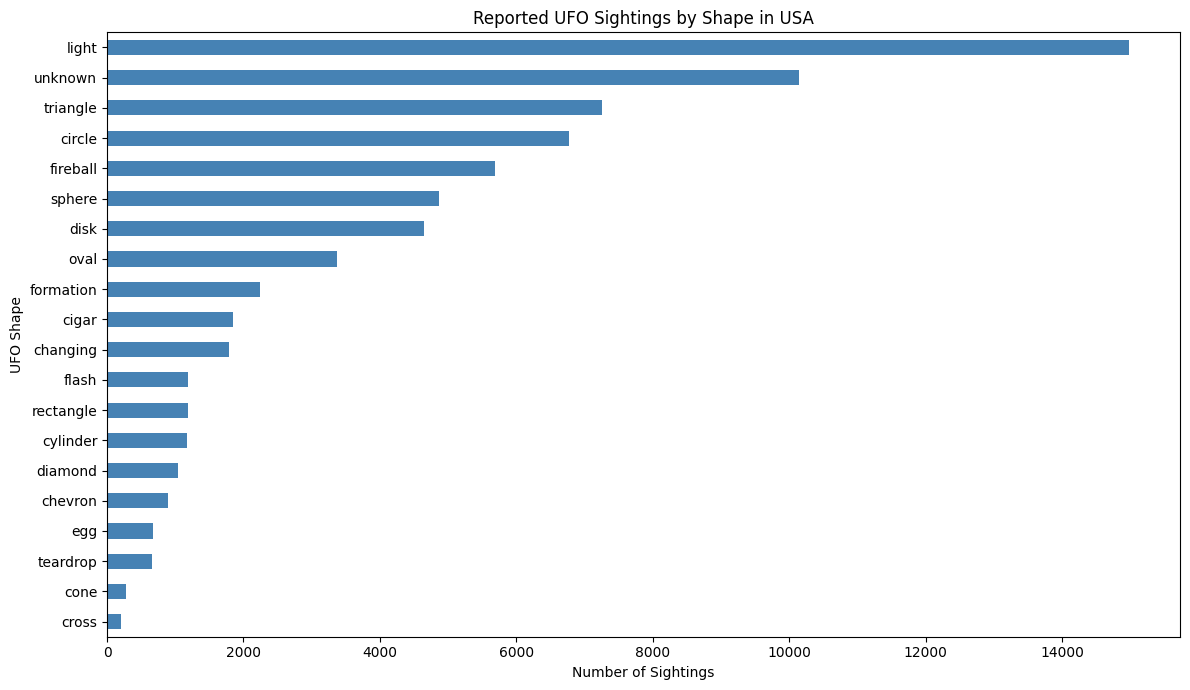

In [44]:
# Calculate counts of each shape inside the US dataset and plot them
plt.figure(figsize=(12, 7))

ufo_us["shape"].value_counts().sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Reported UFO Sightings by Shape in USA")
plt.xlabel("Number of Sightings")
plt.ylabel("UFO Shape")

plt.tight_layout()
plt.show()

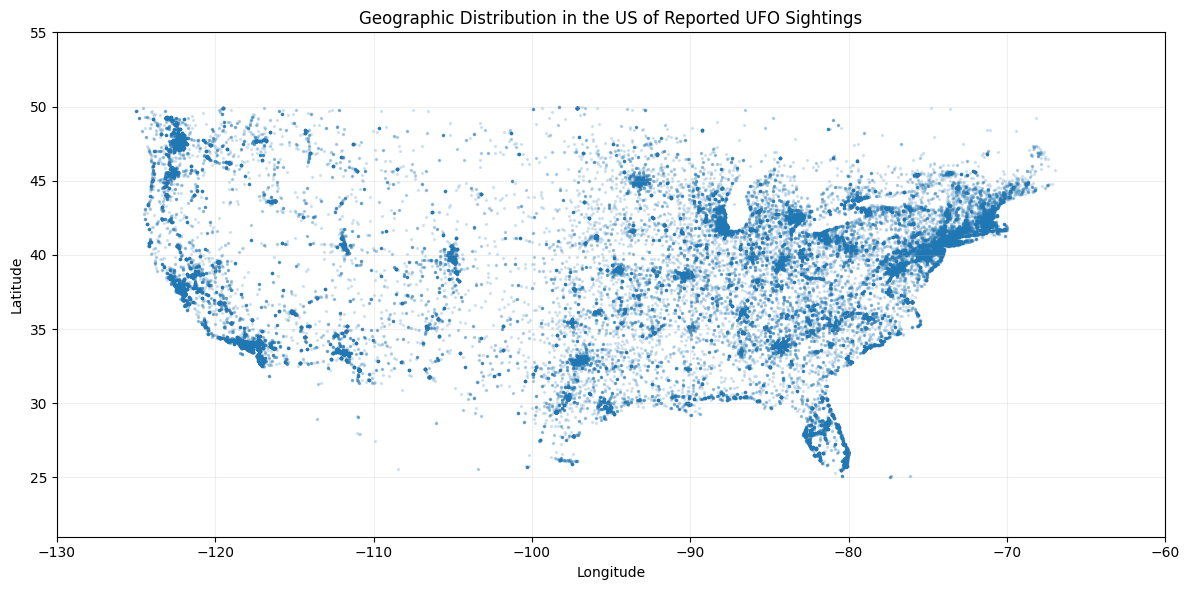

In [45]:
plt.figure(figsize=(12, 6))

plt.scatter(
    ufo_us["longitude"],
    ufo_us["latitude"],
    s=2,
    alpha=0.15
)

plt.title("Geographic Distribution in the US of Reported UFO Sightings")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.xlim(-130, -60)
plt.ylim(21, 55)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

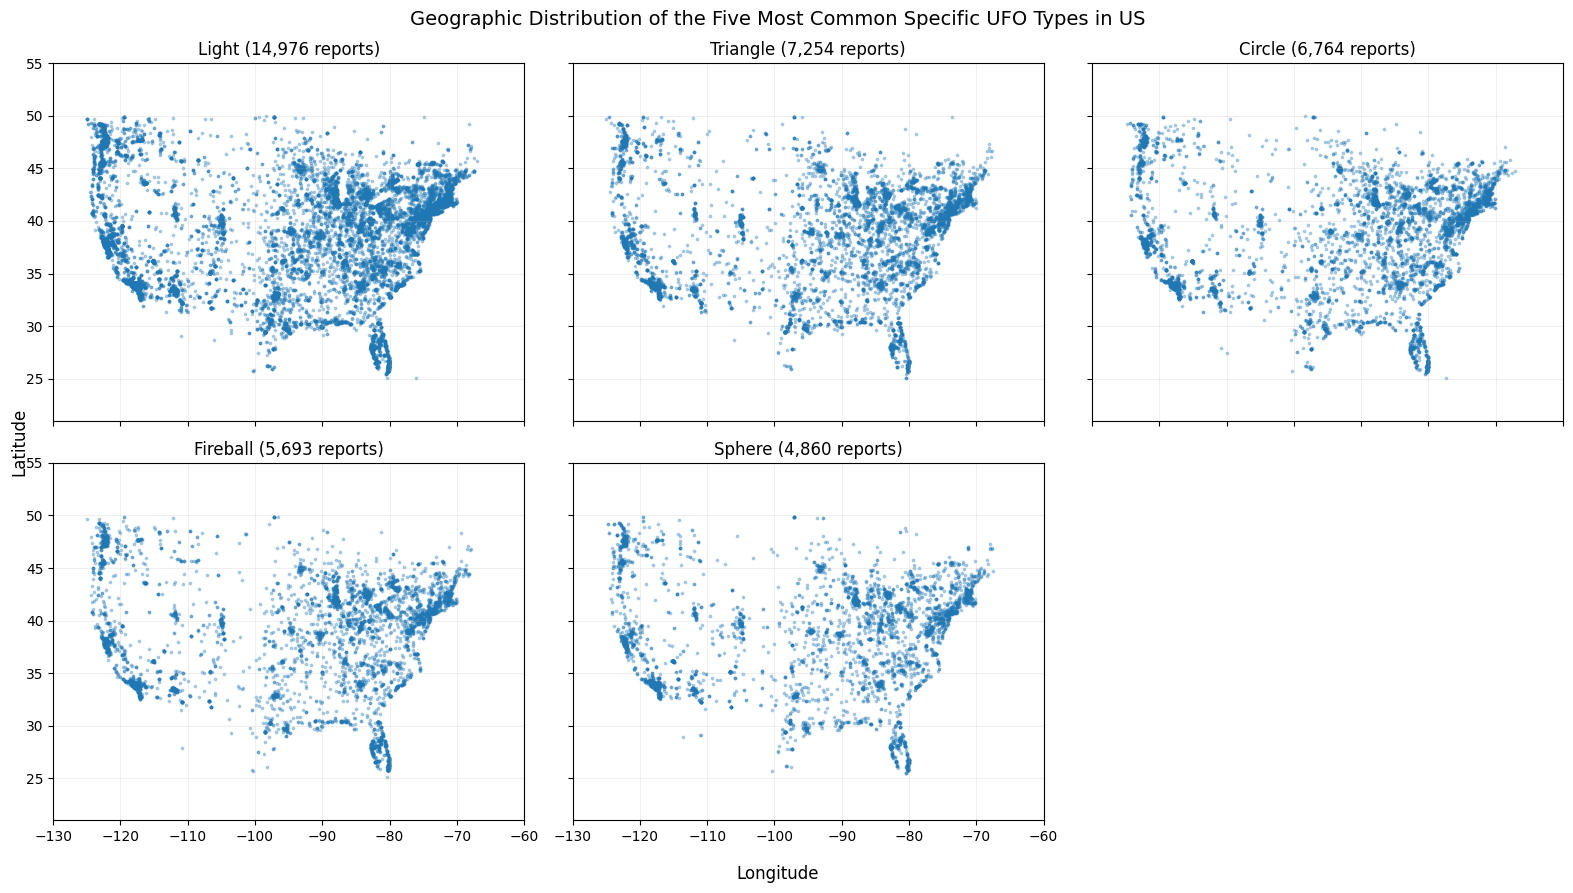

In [46]:
# Select the five most frequent specific UFO types
top_shapes = (
    ufo_us.loc[ufo_us["shape"] != "unknown", "shape"]
    .value_counts()
    .head(5)
    .index
)

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9),
    sharex=True,
    sharey=True
)

for ax, shape in zip(axes.flat, top_shapes):
    subset = ufo_us[ufo_us["shape"] == shape]

    ax.scatter(
        subset["longitude"],
        subset["latitude"],
        s=3,
        alpha=0.3
    )

    ax.set_title(f"{shape.title()} ({len(subset):,} reports)")
    ax.set_xlim(-130, -60)
    ax.set_ylim(21, 55)
    ax.grid(alpha=0.2)

    # Remove unused subplot
for ax in axes.flat[len(top_shapes):]:
    ax.axis("off")

fig.supxlabel("Longitude")
fig.supylabel("Latitude")
fig.suptitle(
    "Geographic Distribution of the Five Most Common Specific UFO Types in US",
    fontsize=14
)

plt.tight_layout()
plt.show()


UFO sightings a cross the US seem to follow the major cities. The top 5 shapes appear to follow the same patter with only the density differing. Let's test this with the

**Kruskal-Wallis Testing**

The Hypotheses are:
 * H0: All UFO shape categories have the same latitude distribution in the US.
 * H1: At least one shape category has a different latitude distribution in the US.

In [47]:
#  common specific shapes in the US
top_shapes2 = (
    ufo_us.loc[ufo_us["shape"] != "unknown", "shape"]
    .value_counts()
    .head(20)
    .index
)

# Prepare US latitude data for each category
latitude_groups2 = [
    ufo_us.loc[
        ufo_us["shape"] == shape,
        "latitude"
    ].dropna().values
    for shape in top_shapes2
]

# Perform Kruskal-Wallis test on US data
h_stat, p_value = kruskal(*latitude_groups2)

print(f"H-statistic: {h_stat:.3f}")
print(f"P-value: {p_value:.6g}")

H-statistic: 42.738
P-value: 0.000871207


The p-value is 0.000871207 is considerably smaller than 0.05 we reject the null hypothesis. This provides evidence that reported UFO shape and latitude are not entirely independent in the way assessed with Kruskal-Wallis test.

However, it doesn't tell us which shapes differ or whether the differences are practically meaningful

In [48]:

# Kruskal-Wallis effect size
n = sum(len(group) for group in latitude_groups2)
k = len(latitude_groups2)

epsilon_squared = max(0, (h_stat - k + 1) / (n - k))

print("Groups analyzed:", k)
print("Total observations:", n)
print(f"Epsilon-squared: {epsilon_squared:.6f}")


Groups analyzed: 19
Total observations: 60730
Epsilon-squared: 0.000407


***The Kruskal-wallis Test Results***

A Kruskal-Wallis test was conducted to determin if the latitude distribution of reported UFP sightingd differ across 19 shap categories. The test produced an H-statistic of 42.738 and a p-value of 0.000871, indicating a statistically significant difference among the groups (p<0.05).

However, the epsilon-square effect size was only 0.000407. this indicates that the differences where extremely small in parctical terms. This suggest that while UFO shape categories are not distributed identically across latitudes, reported shape alone has very little assocation with the latitude.

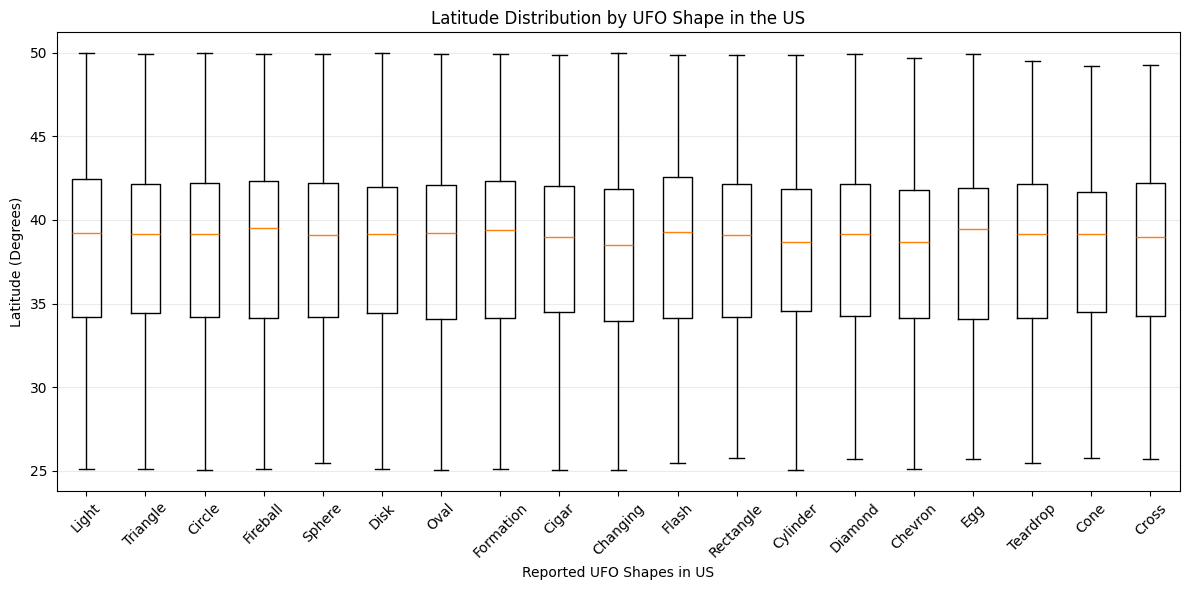

In [49]:
data2 = [
    ufo_us.loc[
        ufo_us["shape"] == shape,
        "latitude"
    ].dropna()
    for shape in top_shapes2
]

plt.figure(figsize=(12, 6))

plt.boxplot(
    data2,
    tick_labels=[s.title() for s in top_shapes2],
    showfliers=False
)

plt.title("Latitude Distribution by UFO Shape in the US")
plt.xlabel("Reported UFO Shapes in US")
plt.xticks(rotation=45)
plt.ylabel("Latitude (Degrees)")
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

This new boxplot is very simular to the world wide box plot. which is to be expected since the US contained 90% of the sightings.

repeating the Kruskal–Wallis, one commonly used estimate is epsilon-squared:
\[
\epsilon^2 = \frac{H-k+1}{N-k}
\]

Where:
- \(H\) = Kruskal–Wallis statistic
- \(k\) = number of groups
- \(N\) = total number of observations included in the test


In [50]:
# Calculate Kruskal-Wallis effect size
k = len(latitude_groups2)
N = sum(len(group) for group in latitude_groups2)

epsilon_squared = max(
    0, (h_stat - k + 1) / (N - k)
)

print(f"US Groups analyzed: {k}")
print(f"Total US observations: {N:,}")
print(f"Epsilon-squared: {epsilon_squared:.6f}")

US Groups analyzed: 19
Total US observations: 60,730
Epsilon-squared: 0.000407


fill in the blank

In [51]:
# create different dataframe to perserve
clusterDf2 =ufo_us[["shape", "latitude", "longitude"]].copy()

print(clusterDf2.dtypes)
print(clusterDf2.isnull().sum())
print(clusterDf2.head())

shape        string[python]
latitude            float64
longitude           float64
dtype: object
shape        0
latitude     0
longitude    0
dtype: int64
      shape   latitude  longitude
0  cylinder  29.883056 -97.941111
1     light  29.384210 -98.581082
3    circle  28.978333 -96.645833
5    sphere  36.595000 -82.188889
7      disk  41.117500 -73.408333


In [52]:
# Convert latitude and longitude from degrees to radians
lat = np.radians(clusterDf2["latitude"])
lon = np.radians(clusterDf2["longitude"])

# Approximate Earth radius in kilometers
R = 6371

# Calculate Cartesian coordinates
clusterDf2["X"] = R * np.cos(lat) * np.cos(lon)
clusterDf2["Y"] = R * np.cos(lat) * np.sin(lon)
clusterDf2["Z"] = R * np.sin(lat)

# Inspect the converted coordinates
display(
    clusterDf2[
        ["shape", "latitude", "longitude", "X", "Y", "Z"]
    ].head(10)
)

,shape,latitude,longitude,X,Y,Z
0,cylinder,29.883056,-97.941111,-763.160919,-5470.966846,3174.231904
1,light,29.384210,-98.581082,-828.312862,-5489.221254,3126.018046
3,circle,28.978333,-96.645833,-645.015861,-5535.919540,3086.614712
5,sphere,36.595000,-82.188889,695.178980,-5067.621332,3798.102318
7,disk,41.117500,-73.408333,1370.541729,-4599.834327,4189.603863
8,disk,33.586111,-86.286111,343.782354,-5296.249895,3524.371114
9,disk,30.294722,-82.984167,671.910736,-5459.800111,3213.838781
10,circle,33.916389,-118.351667,-2510.697111,-4652.814266,3554.906527
11,fireball,35.233333,-82.734444,658.127416,-5162.108850,3675.478407
12,disk,40.668611,-73.527500,1370.237300,-4634.009923,4151.872202


In [53]:
# Extract numerical features for clustering
X = clusterDf2[["X", "Y", "Z"]].to_numpy()

print("K-means input matrix:", X.shape)
print("First five observations:")
print(X[:5])

K-means input matrix: (70877, 3)
First five observations:
[[ -763.16091948 -5470.96684617  3174.2319038 ]
 [ -828.31286233 -5489.22125409  3126.0180463 ]
 [ -645.01586067 -5535.91954037  3086.61471228]
 [  695.17898045 -5067.62133241  3798.10231779]
 [ 1370.54172886 -4599.83432748  4189.60386303]]


In [54]:
# Select three initial centroids
k = 20

rng = np.random.default_rng(42)

indices = rng.choice(
    len(X),
    size=k,
    replace=False
)

centers = X[indices].copy()

print("Initial centroid coordinates:")
print(centers)

Initial centroid coordinates:
[[-2309.02837338 -3649.61460045  4683.83840873]
 [ -678.72446774 -5144.24590905  3696.71585656]
 [ 1284.04037235 -4662.03226395  4148.05213228]
 [-1859.72726665 -4986.66545406  3502.03128812]
 [-2676.24132229 -4300.58385571  3864.24014327]
 [  444.01147113 -4658.57772967  4323.21042168]
 [  702.44927643 -5582.44052398  2988.73950191]
 [  868.06703336 -4564.99384927  4358.54698056]
 [-2446.5740206  -4769.44420503  3443.30052956]
 [  557.42364353 -4981.0975129   3932.88538463]
 [-2190.56122788 -4647.10349099  3767.69314713]
 [-1997.6612005  -4926.2224504   3511.59836786]
 [-1261.85771444 -4684.95993694  4128.98371246]
 [-1266.66267836 -4732.48023975  4072.93965578]
 [-2400.28240134 -3705.03113809  4593.58570831]
 [ 1111.70326398 -4825.45448545  4008.58402203]
 [  842.31574722 -4775.11471197  4132.6050706 ]
 [-2397.19061011 -3787.22264236  4527.69950814]
 [-2446.95928386 -4400.93627132  3903.04896189]
 [ -645.71550739 -4990.10618053  3907.88085675]]


In [55]:
# Set k to match the number of starting centroids
k = len(centers)

print("Number of clusters:", k)
print("Centroid dimensions:", centers.shape)
print("Data dimensions:", X.shape)

Number of clusters: 20
Centroid dimensions: (20, 3)
Data dimensions: (70877, 3)


In [56]:

# Create distance matrix
dist2 = np.empty((len(X), k))

# Calculate squared Euclidean distance
# from each sighting to every centroid
for i in range(k):
    dist2[:, i] = np.sum(
        (X - centers[i]) ** 2,
        axis=1
    )

# Assign each sighting to nearest centroid
clusters2 = np.argmin(dist2, axis=1)

# Save cluster assignments
clusterDf2["cluster"] = clusters2

# Verify cluster sizes
print("Sightings in each cluster:")
print(clusterDf2["cluster"].value_counts().sort_index())

print("\nTotal assigned:",
      clusterDf2["cluster"].value_counts().sum())


Sightings in each cluster:
cluster
0     4379
1     5385
2     9124
3     1264
4     3562
5     7854
6     5273
7     2583
8     4980
9     7832
10    1251
11    1902
12    1406
13    1439
14     293
15    4153
16    2020
17    2325
18    1075
19    2777
Name: count, dtype: int64

Total assigned: 70877


In [57]:

# Recalculate centroids safely
updated_centers2 = centers.copy()

empty_clusters = []

for i in range(k):

    members = X[clusters2 == i]

    if len(members) > 0:
        updated_centers2[i] = members.mean(axis=0)

    else:
        # Keep previous centroid if no sightings assigned
        empty_clusters.append(i)

print("Empty clusters:", len(empty_clusters))

print("Centroids containing NaN:",
      np.isnan(updated_centers2).any())




# old code
# Recalculate centroids based on cluster assignments
#updated_centers2 = np.empty_like(centers)

#for i in range(k):
 #   updated_centers2[i] = X[clusters2 == i].mean(axis=0)

# Compare old and updated centroids
#print("Original centroids:")
#print(centers)

#print("\nUpdated centroids:")
#print(updated_centers2)

# Calculate how far each centroid moved
#movement2 = np.linalg.norm(
#    updated_centers2 - centers,
#    axis=1
#)

#print("\nCentroid movement (km):")
#print(movement2)


Empty clusters: 0
Centroids containing NaN: False


***Automate the iterations***

calculate distances --> Assign sightings to nearest centroid --> calculate new centroids --> measure centroid movement --> repeat until the movement is below 0.01km

In [58]:

# Continue K-means until centroids stabilize
current_centers = updated_centers2.copy()

tolerance = 0.01
max_iterations = 100
iteration = 1

while iteration < max_iterations:

    # Calculate distances to centroids
    dist2 = np.empty((len(X), k))

    for i in range(k):
        dist2[:, i] = np.sum(
            (X - current_centers[i]) ** 2,
            axis=1
        )

    # Assign sightings to nearest centroid
    clusters2 = np.argmin(dist2, axis=1)

    # Recalculate centroids
    new_centers = current_centers.copy()

    for i in range(k):
        members = X[clusters2 == i]

        if len(members) > 0:
            new_centers[i] = members.mean(axis=0)

    # Measure centroid movement
    movement2 = np.linalg.norm(
        new_centers - current_centers,
        axis=1
    )

    iteration += 1

    print(
        f"Iteration {iteration}: "
        f"Maximum movement = {movement2.max():.4f} km"
    )

    # Update centroids
    current_centers = new_centers.copy()

    # Stop when centroids stabilize
    if movement2.max() < tolerance:
        break

# Final assignments based on final centroids
dist2 = np.empty((len(X), k))

for i in range(k):
    dist2[:, i] = np.sum(
        (X - current_centers[i]) ** 2,
        axis=1
    )

clusters2 = np.argmin(dist2, axis=1)
clusterDf2["cluster"] = clusters2

print("\nFinished after", iteration, "iterations")
print("\nFinal cluster sizes:")
print(clusterDf2["cluster"].value_counts().sort_index())


Iteration 2: Maximum movement = 236.9363 km
Iteration 3: Maximum movement = 101.7047 km
Iteration 4: Maximum movement = 56.8752 km
Iteration 5: Maximum movement = 35.7978 km
Iteration 6: Maximum movement = 152.5971 km
Iteration 7: Maximum movement = 54.8434 km
Iteration 8: Maximum movement = 189.4839 km
Iteration 9: Maximum movement = 180.8057 km
Iteration 10: Maximum movement = 203.6242 km
Iteration 11: Maximum movement = 134.7095 km
Iteration 12: Maximum movement = 151.4970 km
Iteration 13: Maximum movement = 91.0523 km
Iteration 14: Maximum movement = 30.9229 km
Iteration 15: Maximum movement = 15.9009 km
Iteration 16: Maximum movement = 15.1512 km
Iteration 17: Maximum movement = 10.1473 km
Iteration 18: Maximum movement = 7.4116 km
Iteration 19: Maximum movement = 6.9401 km
Iteration 20: Maximum movement = 7.8543 km
Iteration 21: Maximum movement = 9.3322 km
Iteration 22: Maximum movement = 16.0181 km
Iteration 23: Maximum movement = 18.7812 km
Iteration 24: Maximum movement = 23.

***Calculate WCSS***
The within-Cluster Sum of Squares (WCSS) measures the sum of square distances between each sighting and its assigned centroid

In [59]:

# Calculate WCSS using final cluster assignments
wcss2 = 0

for i in range(k):
    members = X[clusters2 == i]

    squared_distances = np.sum(
        (members - current_centers[i]) ** 2,
        axis=1
    )

    wcss2 += np.sum(squared_distances)

print(f"Final WCSS (k={k}): {wcss2:,.2f} km²")


Final WCSS (k=20): 3,505,287,861.57 km²


### Initial K-Means Results (k = 3)

K-means clustering was performed on 70,877 UFO sightings using Earth-centered X, Y, and Z coordinates to represent geographic locations.

Three initial centroids were selected, and the algorithm repeatedly assigned sightings to their nearest centroid and recalculated cluster centers.

The algorithm converged after 9 iterations, producing the following results:

| Cluster | Number of Sightings |
|---|---:|
| 0 | 23,630 |
| 1 | 28,811 |
| 2 | 18,436 |

The final Within-Cluster Sum of Squares (WCSS) was **35,242,693,157.03 km²**.

This corresponds to a root mean squared distance of approximately 705 km between sightings and their assigned centroids.

Although the algorithm converged successfully, this result alone does not establish whether three clusters is the most appropriate choice. Additional experiments using different values of k and different initial centroids are necessary to evaluate clustering performance.


After experimenting with differnt K values I see that there is an issue with large k values when their area has no sightings and will attempt to fix this

***Create a resuable function***

In [60]:

def run_kmeans(X, k, seed=42, max_iterations=100,
               tolerance=0.01):

    # Create a random number generator
    rng = np.random.default_rng(seed)

    # Randomly select k observations as centroids
    indices = rng.choice(
        len(X),
        size=k,
        replace=False
    )

    centers = X[indices].copy()

    return centers


In [61]:

test_centers = run_kmeans(X, k=5, seed=42)

print("Centroid dimensions:", test_centers.shape)
print(test_centers)


Centroid dimensions: (5, 3)
[[ 1421.47189319 -4550.14260647  4226.73170638]
 [ -621.08937737 -5347.48169503  3407.09972068]
 [-1997.6612005  -4926.2224504   3511.59836786]
 [  407.48098757 -4781.38634212  4190.69742313]
 [ 1117.66567785 -4731.23454095  4117.75231784]]


In [62]:

def run_kmeans(X, k, seed=42, max_iterations=100,
               tolerance=0.01):

    # Step 1: Select random starting centroids
    rng = np.random.default_rng(seed)

    indices = rng.choice(
        len(X),
        size=k,
        replace=False
    )

    centers = X[indices].copy()

    # Step 2: Calculate squared Euclidean distances
    dist = np.empty((len(X), k))

    for i in range(k):
        dist[:, i] = np.sum(
            (X - centers[i]) ** 2,
            axis=1
        )

    # Step 3: Assign sightings to nearest centroid
    clusters = np.argmin(dist, axis=1)

    return centers, clusters


In [63]:

# Test with 5 clusters
test_centers, test_clusters = run_kmeans(
    X, k=5, seed=42
)

print("Centroid dimensions:", test_centers.shape)

print("\nCluster assignments:")
print(pd.Series(test_clusters).value_counts().sort_index())

print("\nTotal assigned:", len(test_clusters))


Centroid dimensions: (5, 3)

Cluster assignments:
0     7569
1     9118
2    23449
3    17407
4    13334
Name: count, dtype: int64

Total assigned: 70877


recaulate the new centroids

In [64]:

def run_kmeans(X, k, seed=42, max_iterations=100,
               tolerance=0.01):

    # Step 1: Select random starting centroids
    rng = np.random.default_rng(seed)

    indices = rng.choice(
        len(X),
        size=k,
        replace=False
    )

    centers = X[indices].copy()

    # Step 2: Calculate squared Euclidean distances
    dist = np.empty((len(X), k))

    for i in range(k):
        dist[:, i] = np.sum(
            (X - centers[i]) ** 2,
            axis=1
        )

    # Step 3: Assign sightings to nearest centroid
    clusters = np.argmin(dist, axis=1)

    # Step 4: Recalculate centroids
    updated_centers = centers.copy()

    for i in range(k):
        members = X[clusters == i]

        if len(members) > 0:
            updated_centers[i] = members.mean(axis=0)

    # Measure centroid movement
    movement = np.linalg.norm(
        updated_centers - centers,
        axis=1
    )

    return centers, updated_centers, clusters, movement


In [65]:

original, updated, clusters, movement = run_kmeans(
    X, k=5, seed=42
)

print("Original centroids:")
print(original)

print("\nUpdated centroids:")
print(updated)

print("\nCentroid movement (km):")
print(movement)


Original centroids:
[[ 1421.47189319 -4550.14260647  4226.73170638]
 [ -621.08937737 -5347.48169503  3407.09972068]
 [-1997.6612005  -4926.2224504   3511.59836786]
 [  407.48098757 -4781.38634212  4190.69742313]
 [ 1117.66567785 -4731.23454095  4117.75231784]]

Updated centroids:
[[ 1396.76691287 -4496.60863475  4286.30131284]
 [ -332.82099024 -5318.83371982  3430.78935525]
 [-2223.1784557  -4351.13351919  4016.05834915]
 [  256.60740309 -4826.86746831  4118.0702655 ]
 [ 1000.73640531 -4983.98134493  3789.54562058]]

Centroid movement (km):
[ 83.8138425  290.6554116  797.53694831 173.51102374 430.43354635]


ok that worked let's update the function agian so this will run in a loop

In [66]:

def run_kmeans(X, k, seed=42, max_iterations=100,
               tolerance=0.01):

    # Step 1: Select random starting centroids
    rng = np.random.default_rng(seed)

    indices = rng.choice(
        len(X),
        size=k,
        replace=False
    )

    centers = X[indices].copy()

    # Repeat assignments and centroid updates
    for iteration in range(max_iterations):

        # Step 2: Calculate squared Euclidean distances
        dist = np.empty((len(X), k))

        for i in range(k):
            dist[:, i] = np.sum(
                (X - centers[i]) ** 2,
                axis=1
            )

        # Step 3: Assign each sighting
        clusters = np.argmin(dist, axis=1)

        # Step 4: Recalculate centroids
        updated_centers = centers.copy()

        for i in range(k):
            members = X[clusters == i]

            if len(members) > 0:
                updated_centers[i] = members.mean(axis=0)

        # Step 5: Measure centroid movement
        movement = np.linalg.norm(
            updated_centers - centers,
            axis=1
        )

        # Update centers for next iteration
        centers = updated_centers.copy()

        # Stop when centers stabilize
        if movement.max() < tolerance:
            break

    # Reassign using final centers
    dist = np.empty((len(X), k))

    for i in range(k):
        dist[:, i] = np.sum(
            (X - centers[i]) ** 2,
            axis=1
        )

    clusters = np.argmin(dist, axis=1)

    return centers, clusters, iteration + 1, movement


In [67]:

centers, clusters, iterations, movement = run_kmeans(
    X, k=5, seed=42
)

print("Iterations to convergence:", iterations)

print("\nFinal centroid movement (km):")
print(movement)

print("\nFinal cluster sizes:")
print(pd.Series(clusters).value_counts().sort_index())

print("\nTotal sightings:", len(clusters))


Iterations to convergence: 12

Final centroid movement (km):
[0. 0. 0. 0. 0.]

Final cluster sizes:
0    16507
1     8553
2    21023
3    14405
4    10389
Name: count, dtype: int64

Total sightings: 70877


Now we add the WCSS to the same function

In [68]:

def run_kmeans(X, k, seed=42, max_iterations=100,
               tolerance=0.01):

    # Step 1: Select random starting centroids
    rng = np.random.default_rng(seed)

    indices = rng.choice(
        len(X),
        size=k,
        replace=False
    )

    centers = X[indices].copy()

    # Repeat assignments and centroid updates
    for iteration in range(max_iterations):

        # Step 2: Calculate squared Euclidean distances
        dist = np.empty((len(X), k))

        for i in range(k):
            dist[:, i] = np.sum(
                (X - centers[i]) ** 2,
                axis=1
            )

        # Step 3: Assign each sighting
        clusters = np.argmin(dist, axis=1)

        # Step 4: Recalculate centroids
        updated_centers = centers.copy()

        for i in range(k):
            members = X[clusters == i]

            if len(members) > 0:
                updated_centers[i] = members.mean(axis=0)

        # Step 5: Measure centroid movement
        movement = np.linalg.norm(
            updated_centers - centers,
            axis=1
        )

        # Calculate WCSS
        wcss = np.sum(
            dist[np.arange(len(X)), clusters]
        )

        # Update centers for next iteration
        centers = updated_centers.copy()

        # Stop when centers stabilize
        if movement.max() < tolerance:
            break

    # Reassign using final centers
    dist = np.empty((len(X), k))

    for i in range(k):
        dist[:, i] = np.sum(
            (X - centers[i]) ** 2,
            axis=1
        )

    clusters = np.argmin(dist, axis=1)

    return centers, clusters, iteration + 1, movement , wcss


In [69]:

centers, clusters, iterations, movement, wcss = run_kmeans(
    X, k=5, seed=42
)

print("Number of clusters:", len(centers))
print("Iterations:", iterations)
print(f"WCSS: {wcss:,.2f} km²")


Number of clusters: 5
Iterations: 12
WCSS: 21,054,595,742.70 km²


In [70]:

# Run K-means 5 times with different random seeds
results = []

for seed in range(5):

    centers, clusters, iterations, movement, wcss = run_kmeans(
        X, k=5, seed=seed
    )

    results.append({
        "k": 5,
        "seed": seed,
        "iterations": iterations,
        "wcss": wcss
    })

# Create a table of experiment results
results_df = pd.DataFrame(results)

display(results_df)


,k,seed,iterations,wcss
0,5,0,13,1.934066e+10
1,5,1,24,2.105460e+10
2,5,2,25,2.105460e+10
3,5,3,16,2.105460e+10
4,5,4,19,1.934066e+10


In [71]:

# Display WCSS in billions for easier comparison
results_df["wcss_billions"] = (
    results_df["wcss"] / 1e9
)

display(
    results_df[
        ["k", "seed", "iterations", "wcss_billions"]
    ].round(3)
)


,k,seed,iterations,wcss_billions
0,5,0,13,19.341
1,5,1,24,21.055
2,5,2,25,21.055
3,5,3,16,21.055
4,5,4,19,19.341


***Evaluating the number of clusters using Wcss and the elbow method***

The initial K-means experiments demonstrated that the algorithm can produce different clustering results depending on the randomly selected starting centroids. When five clusters were tested using different random seeds, the algorithm converged successfully but produced two different WCSS values, approximately 19.34 billion km² and 21.05 billion km².

This demonstrates that K-means can converge to different local solutions even when the dataset and number of clusters remain unchanged.

To investigate the most appropriate number of geographic clusters for the UFO sightings dataset, the next experiment will:

1. Test values of **k from 2 through 20**.
2. Run K-means **five times for each k**, using different random seeds.
3. Record the number of iterations and final WCSS from each run.
4. Identify the lowest WCSS obtained for each value of k.
5. Create an elbow plot to examine whether adding more clusters produces diminishing improvements.

WCSS measures the total squared distance between each sighting and its assigned cluster centroid. Lower WCSS indicates more geographically compact clusters, but increasing the number of clusters generally decreases WCSS.

The elbow method attempts to identify a point where additional clusters provide progressively smaller improvements. The elbow is a heuristic, so it may not provide a single clear or objectively optimal number of clusters.

The goal is to identify a reasonable balance between geographic clustering accuracy and model complexity.

run the repeated k-means experiment

the idea here is to ues two nested loops. the outside loop changes the number of clusters from 2 through 20. the inside loop runs k-means five times for each value of k.

In [72]:

# Test K-means for k = 2 through 20
# Use five different random starting configurations

experiment_results = []

for k_value in range(2, 21):

    for seed in range(5):

        centers, clusters, iterations, movement, wcss = run_kmeans(
            X,
            k=k_value,
            seed=seed
        )

        experiment_results.append({
            "k": k_value,
            "seed": seed,
            "iterations": iterations,
            "wcss": wcss
        })

    print(f"Completed k = {k_value}")

# Convert results into a DataFrame
experiment_df = pd.DataFrame(experiment_results)

print("\nTotal experiments:", len(experiment_df))

display(experiment_df.head(10))


Completed k = 2
Completed k = 3
Completed k = 4
Completed k = 5
Completed k = 6
Completed k = 7
Completed k = 8
Completed k = 9
Completed k = 10
Completed k = 11
Completed k = 12
Completed k = 13
Completed k = 14
Completed k = 15
Completed k = 16
Completed k = 17
Completed k = 18
Completed k = 19
Completed k = 20

Total experiments: 95


,k,seed,iterations,wcss
0,2,0,8,5.113737e+10
1,2,1,9,5.113737e+10
2,2,2,5,5.113737e+10
3,2,3,6,5.113732e+10
4,2,4,5,5.113737e+10
5,3,0,9,3.532142e+10
6,3,1,12,3.524151e+10
7,3,2,14,3.597903e+10
8,3,3,9,3.597903e+10
9,3,4,15,3.532142e+10


In [73]:

# Summarize results for each number of clusters
wcss_summary = (
    experiment_df
    .groupby("k")
    .agg(
        best_wcss=("wcss", "min"),
        average_wcss=("wcss", "mean"),
        worst_wcss=("wcss", "max"),
        average_iterations=("iterations", "mean")
    )
    .reset_index()
)

# Express WCSS in billions for readability
wcss_summary["best_wcss_billions"] = (
    wcss_summary["best_wcss"] / 1e9
)

wcss_summary["average_wcss_billions"] = (
    wcss_summary["average_wcss"] / 1e9
)

display(
    wcss_summary[
        [
            "k",
            "best_wcss_billions",
            "average_wcss_billions",
            "average_iterations"
        ]
    ].round(3)
)


,k,best_wcss_billions,average_wcss_billions,average_iterations
0,2,51.137,51.137,6.6
1,3,35.242,35.568,11.8
2,4,27.084,27.360,16.8
3,5,19.341,20.369,19.4
4,6,13.654,15.532,23.0
5,7,12.106,12.350,50.6
6,8,9.672,10.253,29.4
7,9,8.377,8.991,35.4
8,10,7.801,8.200,27.0
9,11,6.566,7.095,25.2


### WCSS Comparison and Elbow Plot

After running K-means five times for each number of clusters, the minimum and average WCSS values were calculated.

The graph below compares the number of clusters against WCSS. The minimum WCSS represents the best clustering result obtained from the five random initializations, while the average WCSS provides information about variation between runs.

A distinct bend in the curve would suggest that adding further clusters produces diminishing improvements in geographic compactness.

The shape of the resulting curve will be examined to determine whether a reasonable number of geographic clusters can be identified.

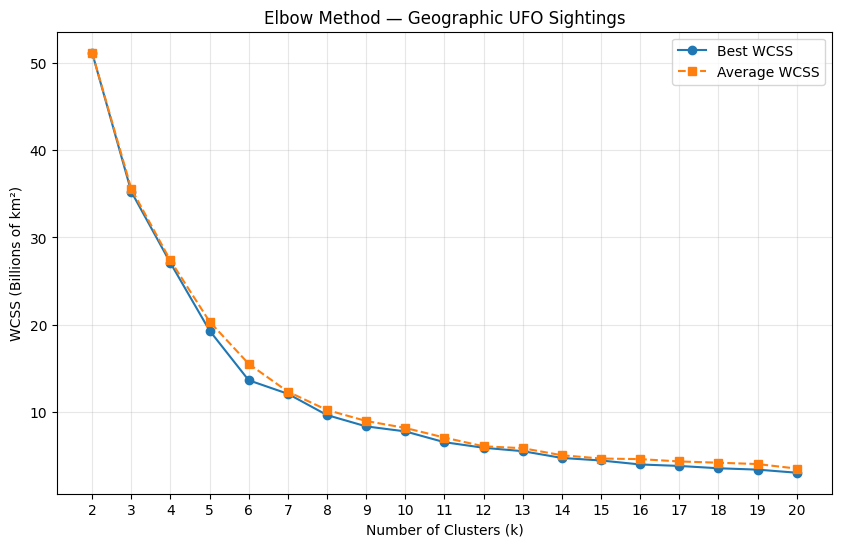

In [74]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    wcss_summary["k"],
    wcss_summary["best_wcss_billions"],
    marker="o",
    label="Best WCSS"
)

plt.plot(
    wcss_summary["k"],
    wcss_summary["average_wcss_billions"],
    marker="s",
    linestyle="--",
    label="Average WCSS"
)

plt.title("Elbow Method — Geographic UFO Sightings")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS (Billions of km²)")

plt.xticks(range(2, 21))
plt.grid(alpha=0.3)
plt.legend()

plt.show()


### Interpretation of the Elbow Method

K-means clustering was performed on 70,877 UFO sightings using Earth-centered X, Y, and Z geographic coordinates. Values of k from 2 through 20 were tested, with five different random initializations for each value, resulting in 95 clustering experiments.

The best WCSS decreased from approximately 51.14 billion km² at k = 2 to 13.65 billion km² at k = 6. Beyond six clusters, the overall rate of improvement generally slowed, although additional decreases occurred at higher values of k.

The elbow plot suggests that **k = 6 may represent a reasonable balance between geographic compactness and the number of clusters**. However, the curve does not show one definitive elbow, so six clusters should be considered a candidate rather than a mathematically proven optimum.

Differences between the minimum and average WCSS also indicate that random centroid initialization can affect the final clustering results.

Because this analysis uses geographic coordinates, the clusters represent areas where reported sightings are geographically concentrated. They do not independently demonstrate differences in UFO activity or establish a relationship between cluster locations and population density.

The next step is to visualize the six-cluster solution and examine whether the resulting geographic groupings are interpretable.

In [75]:

# Find the best seed for k = 6
k6_results = experiment_df[
    experiment_df["k"] == 6
].sort_values("wcss")

display(k6_results)

# Select the best-performing seed
best_seed = int(k6_results.iloc[0]["seed"])

print("Best seed for k=6:", best_seed)


,k,seed,iterations,wcss
23,6,3,18,1.365427e+10
22,6,2,21,1.365438e+10
21,6,1,23,1.365552e+10
20,6,0,18,1.725389e+10
24,6,4,35,1.944277e+10


Best seed for k=6: 3


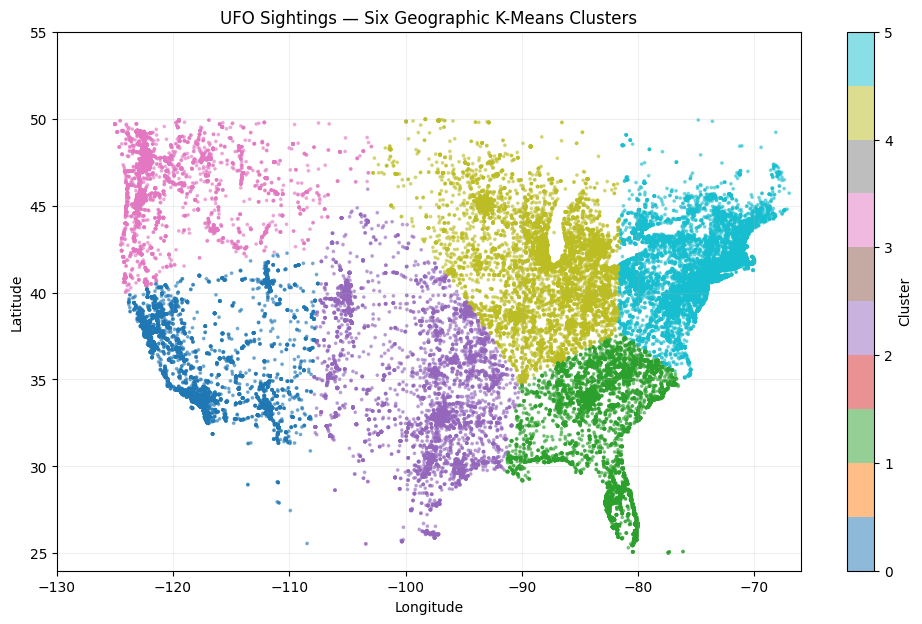

In [76]:

# Reproduce the best six-cluster solution
final_centers, final_clusters, final_iterations, \
final_movement, final_wcss = run_kmeans(
    X, k=6, seed=3
)

# Create a copy of the geographic dataset
ufo_final = clusterDf2.copy()

# Add the final cluster assignments
ufo_final["cluster"] = final_clusters

# Plot the geographic clusters
plt.figure(figsize=(12, 7))

scatter = plt.scatter(
    ufo_final["longitude"],
    ufo_final["latitude"],
    c=ufo_final["cluster"],
    cmap="tab10",
    s=3,
    alpha=0.5
)

plt.title("UFO Sightings — Six Geographic K-Means Clusters")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.xlim(-130, -66)
plt.ylim(24, 55)

plt.colorbar(scatter, label="Cluster")
plt.grid(alpha=0.2)
plt.show()


In [77]:

# Compare UFO shape distributions across clusters

# Count each UFO shape within each cluster
shape_counts_by_cluster = pd.crosstab(
    ufo_final["cluster"],
    ufo_final["shape"]
)

# Convert counts into percentages
shape_percentages = (
    shape_counts_by_cluster
    .div(shape_counts_by_cluster.sum(axis=1), axis=0)
    * 100
)

# Display the most common shapes overall
top_shapes = ufo_final["shape"].value_counts().head(10).index

print("Percentage of sightings by shape within each cluster:")

display(
    shape_percentages[top_shapes].round(2)
)


Percentage of sightings by shape within each cluster:


shape,light,unknown,triangle,circle,fireball,sphere,disk,oval,formation,cigar
cluster,,,,,,,,,,
0,21.39,14.12,9.44,9.41,7.51,7.23,6.90,4.59,3.69,2.24
1,20.60,14.15,10.25,10.09,8.80,7.00,6.04,4.94,2.80,2.51
2,21.08,15.81,10.81,8.52,6.32,6.43,6.37,4.76,2.83,3.15
3,24.02,14.88,8.92,8.86,8.75,6.92,5.61,4.54,3.06,2.09
4,21.17,13.76,11.67,9.54,8.67,6.58,6.47,4.38,3.22,2.56
5,19.89,13.99,9.94,10.19,8.03,6.90,7.21,5.17,3.10,2.96


### Comparing UFO Shape Distributions Across Geographic Clusters

After identifying six geographic clusters using K-means, the next step is to investigate whether the distribution of reported UFO shapes differs between these regions.

Although geographic coordinates were used to create the clusters, UFO shape was not included as a clustering variable. This allows us to examine shape distributions independently of the clustering process.

Because the clusters contain different numbers of sightings, percentages will be used instead of raw counts. This provides a more meaningful comparison of the relative frequency of each reported shape across geographic regions.

The analysis will initially focus on the ten most frequently reported shapes.

In [78]:

# Count UFO shapes within each geographic cluster
shape_counts_by_cluster = pd.crosstab(
    ufo_final["cluster"],
    ufo_final["shape"]
)

# Calculate percentages within each cluster
shape_percentages = (
    shape_counts_by_cluster
    .div(shape_counts_by_cluster.sum(axis=1), axis=0)
    * 100
)

# Identify the 10 most common shapes overall
top_shapes = (
    ufo_final["shape"]
    .value_counts()
    .head(10)
    .index
)

# Display percentages
print("UFO Shape Percentages by Geographic Cluster")

display(
    shape_percentages[top_shapes].round(2)
)

# Verify that all shape percentages total 100%
print("\nTotal percentage for each cluster:")
print(shape_percentages.sum(axis=1).round(2))


UFO Shape Percentages by Geographic Cluster


shape,light,unknown,triangle,circle,fireball,sphere,disk,oval,formation,cigar
cluster,,,,,,,,,,
0,21.39,14.12,9.44,9.41,7.51,7.23,6.90,4.59,3.69,2.24
1,20.60,14.15,10.25,10.09,8.80,7.00,6.04,4.94,2.80,2.51
2,21.08,15.81,10.81,8.52,6.32,6.43,6.37,4.76,2.83,3.15
3,24.02,14.88,8.92,8.86,8.75,6.92,5.61,4.54,3.06,2.09
4,21.17,13.76,11.67,9.54,8.67,6.58,6.47,4.38,3.22,2.56
5,19.89,13.99,9.94,10.19,8.03,6.90,7.21,5.17,3.10,2.96



Total percentage for each cluster:
cluster
0    100.0
1    100.0
2    100.0
3    100.0
4    100.0
5    100.0
dtype: float64


### Interpretation of UFO Shape Distributions Across Geographic Clusters

The percentage distribution of reported UFO shapes was compared across the six geographic clusters identified by K-means.

Light was the most commonly reported shape in every geographic region, representing approximately 19.89% to 24.02% of sightings. Unknown was also consistently common across all six clusters.

Some regional differences were observed. Triangle sightings represented 11.67% of reports in the Midwest/Great Lakes cluster, compared with 8.92% in the Northwest cluster. Fireball sightings were most common proportionally in the Southeast cluster (8.80%) and least common in the South-central cluster (6.32%).

Although these differences suggest some geographic variation, the overall shape distributions were relatively similar across regions.

Because K-means grouped sightings using geographic coordinates rather than reported shapes, this comparison provides a separate descriptive examination of shape characteristics within the resulting clusters.

These results do not establish a causal relationship between geography and reported UFO shape. Additional statistical testing would be necessary to determine whether the differences are statistically significant.

### Chi-Square Test of Independence: Geographic Cluster and UFO Shape

A chi-square test of independence will be used to investigate whether reported UFO shape is associated with the geographic clusters produced by K-means.

The null hypothesis is that reported shape and geographic cluster are independent. The alternative hypothesis is that they are associated.

Because the dataset includes a large number of sightings, Cramér's V will also be calculated to estimate the strength of any observed association.

This test complements the earlier Kruskal–Wallis analysis by comparing categorical shape distributions across geographic clusters rather than comparing latitude distributions between shape categories.

In [79]:

from scipy.stats import chi2_contingency
import numpy as np

# Use all shape categories, not just the top ten
contingency_table = pd.crosstab(
    ufo_final["cluster"],
    ufo_final["shape"]
)

# Chi-square test of independence
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

# Calculate Cramer's V
n = contingency_table.to_numpy().sum()
r, c = contingency_table.shape

cramers_v = np.sqrt(
    chi2 / (n * min(r - 1, c - 1))
)

print(f"Chi-square statistic: {chi2:.3f}")
print(f"P-value: {p_value:.6g}")
print(f"Degrees of freedom: {dof}")
print(f"Cramer's V: {cramers_v:.4f}")

print("\nExpected counts below 5:",
      (expected < 5).sum())


Chi-square statistic: 404.501
P-value: 8.41107e-40
Degrees of freedom: 95
Cramer's V: 0.0338

Expected counts below 5: 0


In [80]:

# Compare worldwide and US-focused datasets
worldwide_count = len(ufo_geo)
us_count = len(ufo_us)

print(f"Worldwide cleaned sightings: {worldwide_count:,}")
print(f"US-region sightings: {us_count:,}")
print(f"Sightings excluded: {worldwide_count - us_count:,}")
print(f"Percentage retained: {us_count / worldwide_count * 100:.2f}%")


Worldwide cleaned sightings: 78,382
US-region sightings: 70,877
Sightings excluded: 7,505
Percentage retained: 90.43%


### Chi-Square Test Results and Interpretation

A chi-square test of independence was performed to determine whether reported UFO shape was associated with the six geographic clusters generated by K-means.

The test produced a chi-square statistic of 404.501 with 95 degrees of freedom and a p-value of approximately 8.41 × 10⁻⁴⁰. Since the p-value was below the 0.05 significance threshold, the null hypothesis of independence was rejected.

However, Cramér's V was only 0.0338, indicating an extremely weak association between geographic cluster and reported UFO shape.

All expected cell frequencies were at least five, satisfying the expected-frequency assumption for the chi-square approximation.

These results suggest that while the distribution of reported UFO shapes differs statistically between geographic regions, the observed differences are small in practical terms.

This finding is consistent with the earlier Kruskal–Wallis analysis, which also identified statistically significant geographic differences with a very small effect size. However, the two tests evaluate different aspects of the relationship and their effect sizes are not directly interchangeable.

Overall, the evidence suggests that geographic location is not strongly associated with the shape of a reported UFO sighting.

## Final Discussion and Conclusions

### Did the Clustering Results Support the Hypothesis?

The objective of this analysis was to determine whether UFO sightings could be grouped into meaningful geographic regions and whether the reported shapes of UFOs differed between those regions.

Using a manually implemented K-means algorithm, 70,877 UFO sightings were grouped based on their geographic coordinates. The elbow method was used to evaluate values of k from 2 through 20, with five random starting configurations for each value.

The elbow plot suggested that six clusters provided a reasonable balance between geographic compactness and the number of clusters, although no single definitive elbow was identified.

The resulting six clusters represented recognizable geographic regions across the United States, supporting the hypothesis that K-means could organize reported sightings into interpretable geographic groups.

However, the relationship between geographic region and reported UFO shape was much weaker.

A chi-square test of independence found a statistically significant association between geographic cluster and reported shape (χ² = 404.501, p < 0.001). However, Cramér's V was only 0.0338, indicating an extremely weak association.

These results suggest that while reported UFO shapes vary slightly between geographic regions, geography alone provides little information about which shape is likely to be reported.

### Was K-Means an Appropriate Method?

K-means was useful for organizing a large geographic dataset into smaller, interpretable groups. Its iterative process provided a clear way to examine geographic concentrations and compare sighting characteristics between regions.

Converting latitude and longitude into Earth-centered X, Y, and Z coordinates also allowed geographic distances to be represented more appropriately than treating degrees of latitude and longitude as equivalent units.

However, K-means has several limitations for this type of analysis.

First, it requires the number of clusters to be selected in advance. Although the elbow method suggested six clusters, the result was not definitive.

Second, K-means assigns every observation to a cluster, even when geographic boundaries are not naturally distinct.

Third, the algorithm is sensitive to its starting centroids. Multiple random initializations produced different WCSS values, demonstrating that K-means can converge to different local solutions.

Finally, geographic concentrations of reported sightings may reflect population density, reporting behavior, and differences in data collection rather than actual differences in UFO activity.

### How Could This Analysis Be Improved?

Several improvements could strengthen future analysis:

- **Population normalization:** Compare sightings relative to local population rather than raw report density.
- **Alternative clustering methods:** Evaluate DBSCAN or HDBSCAN, which can identify density-based clusters without requiring a predetermined number of groups.
- **Additional variables:** Incorporate sighting duration, time of day, or year to investigate whether reports share other characteristics.
- **Temporal analysis:** Examine whether geographic or shape patterns change across different decades.
- **Clustering validation:** Compare candidate cluster counts using additional measures of cluster quality and stability.

### Overall Conclusion

K-means successfully identified six interpretable geographic regions within the UFO sightings dataset. However, comparisons of reported shapes across those regions revealed only extremely weak differences.

The analysis demonstrates that **geographic clustering can be useful for describing where UFO sightings are reported, but it does not necessarily explain differences in the characteristics of those sightings**.

The results also highlight the importance of distinguishing statistical significance from practical significance when working with large datasets.